# 🌱 EnergiaClara AI — Global Solution / Citizen Assist AI
### Simulador de economia e sustentabilidade energética residencial

**Disciplina:** Soluções em Energias Renováveis e Sustentáveis  
**Público:** consumidores residenciais brasileiros  
**Equipe:** Caio Henrique Ferraz da Silva – RM:568992 | Enzo Caruso Peter – RM: 570908
**Ambiente:** Google Colab — projeto autônomo, sem dependência de outros trabalhos.

> **Pergunta central:** para uma mesma residência e período de referência, o que muda ao substituir lâmpadas por LED e/ou incorporar geração solar fotovoltaica, considerando consumo, custos, retorno financeiro e sustentabilidade?

**O que você encontrará:** fundamentação, dados editáveis, cálculos em Python, comparações de cenários, gráficos, análise de sensibilidade, assistente baseado em regras, referências, auditoria de parâmetros, testes automáticos, relato de usabilidade e exportação das evidências.

**Como executar:** selecione `Ambiente de execução → Executar tudo`. Para alterar a residência, edite a **seção 3**, execute o formulário e as células seguintes. Para fazer uma nova pergunta, edite e execute apenas a **seção 8**.

**Transparência dos dados:** os valores padrão de consumo, tarifa, lâmpadas, investimentos e perdas são estimativas didáticas editáveis. Quando houver consulta bem-sucedida à NASA POWER, a irradiação é uma referência climática histórica. O simulador não prevê a fatura regulatória, a geração medida ou a economia garantida.

**Validação de usabilidade:** foi relatado um teste real com um participante anônimo (P1), que compreendeu os gráficos, conseguiu utilizar o programa e sugeriu melhorar a organização das respostas. Essa melhoria foi implementada na seção 8 e avaliada visualmente pelo responsável do projeto. Um novo teste por P1 ainda não foi informado; o Colab não o presumirá.


## 1. Fundamentação e fontes verificáveis

| Assunto | Fonte oficial | Uso nesta análise |
|---|---|---|
| Conta de energia | [ANEEL — Custo da energia](https://www.gov.br/aneel/pt-br/assuntos/tarifas/entenda-a-tarifa/custo-da-energia-que-chega-aos-consumidores) | Distinguir tarifa simplificada de fatura real (tributos, encargos e CIP). |
| Geração distribuída | [ANEEL — Micro e minigeração distribuída](https://www.gov.br/aneel/pt-br/assuntos/geracao/geracao-distribuida) | Descrever compensação, custo de disponibilidade e limitações. |
| Eficiência de lâmpadas | [INMETRO — Eficiência LED](https://www.gov.br/inmetro/pt-br/acesso-a-informacao/perguntas-frequentes/avaliacao-da-conformidade/lampadas-e-luminarias-led-portaria-inmetro-no-231-2026-consumidores/para-pagar-uma-conta-de-energia-mais-barata-devo-comprar-lampadas-e-luminarias-de-luz-201cfria201d) | Comparar **lúmens** e eficácia luminosa (lm/W), além de watts. |
| Insolação | [NASA POWER — API de climatologia](https://power.larc.nasa.gov/docs/services/api/temporal/climatology/) | Opcional: obter irradiação histórica por coordenadas geográficas. |
| Emissões | [MCTI/SIRENE — Fatores de emissão](https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/sirene/dados-e-ferramentas/fatores-de-emissao) e [nota MCTI sobre 2023](https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/noticias/2024/02/fator-de-emissao-de-co2-na-geracao-de-energia-eletrica-no-brasil-em-2023-e-o-menor-em-12-anos) | **0,0385 t CO₂/MWh = 0,0385 kg CO₂/kWh**, média anual histórica de 2023 (exemplo contábil; não é fator vigente nem redução causal). |

**Consulta e transparência:** a [ANEEL explica as condições da geração distribuída](https://www.gov.br/aneel/pt-br/assuntos/geracao-distribuida), inclusive custos mínimos; para o grupo B, o custo de disponibilidade depende da ligação (30/50/100 kWh equivalentes). Não aplicamos esses valores automaticamente, porque o tipo de ligação e a regra de compensação de cada caso não foram informados.

**Diferencie:** fonte oficial ≠ dado individual medido. O consumo de `250 kWh`, a tarifa de `R$ 0,90/kWh`, as potências, os investimentos e o `PR=0,80` são **valores didáticos**; o usuário poderá substituí-los. O fator de 2023 serve para ilustrar um indicador *contábil* de emissões, **não** uma redução causal/certificada de CO₂.

**Consulta de valores que mudam com o tempo:** [Dados Abertos ANEEL — Tarifas de aplicação](https://dadosabertos.aneel.gov.br/dataset/tarifas-distribuidoras-energia-eletrica) (TE + TUSD, sem todos os tributos da conta), [Sistema PBE Inmetro — Lâmpadas](https://www.gov.br/inmetro/pt-br/assuntos/regulamentacao/avaliacao-da-conformidade/programa-brasileiro-de-etiquetagem/tabelas-de-eficiencia-energetica/lampadas) (modelo e especificações). A existência dessas bases **não valida automaticamente** os valores padrão do formulário. A seção 13 documenta como os números reais foram obtidos.


## 2. Modelo matemático e limites

Consumo de aparelhos:

$$E_{\mathrm{kWh}}=\frac{P_{\mathrm{W}}\,n\,h_{\mathrm{dia}}\,d}{1000}$$

Ganho pela troca por LED:

$$\Delta E_{LED}=\frac{(P_{antiga}-P_{LED})\,n\,h_{\mathrm{dia}}\,d}{1000}$$

Geração solar fotovoltaica aproximada:

$$G_{FV}=P_{FV}(\mathrm{kWp})\times HSP(\mathrm{h/dia})\times d\times PR$$

Aqui `HSP` é aproximada a partir da irradiação global **horizontal** em kWh/m²/dia. Para telhados inclinados e com sombras, a irradiação efetiva sobre os módulos pode diferir. `PR` resume perdas e é hipótese editável.

A solar **não diminui o consumo físico** da casa: substitui, em parte, a energia demandada da rede. O cálculo `max(0, consumo − geração)` é apenas um **saldo energético hipotético mensal**, **não** a energia faturada ou compensada. Para `LED + Solar`, primeiro reduzimos o consumo com LED e só então limitamos a geração solar utilizada ao consumo residual, evitando somar economia duas vezes.

**Economia BRUTA teórica** = redução hipotética de demanda de rede × tarifa. A economia **AJUSTADA PARA ANÁLISE** usa um fator editável entre 0 e 1 **apenas no componente solar**; o LED mantém sua economia energética bruta. Esse fator não é tarifa oficial nem regra de compensação.

**Custo energético bruto teórico** = energia do saldo hipotético × tarifa digitada; **payback simples** = investimento ÷ potencial mensal de economia. São estimativas grosseiras, especialmente para solar: ignoram horário de geração/consumo, custo de disponibilidade, compensação, tributos, manutenção, degradação, financiamento, sazonalidade e condições do imóvel. O gráfico de 60 períodos usa **meses padronizados de 30 dias**, não previsão de faturamento real.

## 3. Dados variáveis — formulário do Colab

**Edite os campos abaixo sem alterar o código.** O consumo, a tarifa e os custos iniciais continuam sendo EXEMPLOS. A consulta à NASA POWER já vem selecionada; ela pode fornecer um dado climático histórico real caso a API responda. Você pode optar pelo HSP manual. Se a consulta falhar, o simulador volta ao HSP manual **e avisa**.

- **Período e consumo:** a entrada de consumo é mensal (referência de 30 dias); para outros períodos, assumimos consumo médio diário constante e multiplicamos por `dias/30`.
- **Tarifa:** valor aproximado informado pelo usuário; não é preço oficial atualizado automaticamente.
- **Lúmens:** informações estimadas ou extraídas da embalagem (não presumir que potências semelhantes signifiquem luminosidade igual).
- **Fator de aproveitamento financeiro solar:** é um teste de sensibilidade, **não** uma regra real de compensação. Seus efeitos aparecem na tabela, no gráfico financeiro e nas respostas do assistente.
- **Fator CO₂:** valor histórico de 2023; altere se tiver outro fator oficial identificado por ano e método.

In [2]:
#@title 3. Formulário — edite os parâmetros e clique em Executar
consumo_mensal_kwh = 250.0 #@param {type:"number"}
tarifa_rs_kwh = 0.90 #@param {type:"number"}
dias = 30 #@param {type:"integer"}

#@markdown **Lâmpadas**
quantidade_lampadas = 10 #@param {type:"integer"}
potencia_antiga_w = 60.0 #@param {type:"number"}
potencia_led_w = 9.0 #@param {type:"number"}
horas_lampadas_dia = 5.0 #@param {type:"number"}
lumens_antiga = 800.0 #@param {type:"number"}
lumens_led = 800.0 #@param {type:"number"}
investimento_led_rs = 150.0 #@param {type:"number"}

#@markdown **Geração solar**
cidade = "São Paulo (SP)" #@param ["São Paulo (SP)","Rio de Janeiro (RJ)","Belo Horizonte (MG)","Curitiba (PR)","Recife (PE)","Porto Alegre (RS)"]
fonte_hsp = "NASA POWER (API histórica)" #@param ["Manual (hipótese)","NASA POWER (API histórica)"]
hsp_manual = 4.5 #@param {type:"number"}
potencia_solar_kwp = 1.0 #@param {type:"number"}
performance_ratio = 0.80 #@param {type:"number"}
investimento_solar_rs = 5000.0 #@param {type:"number"}

#@markdown **Impactos e análise de sensibilidade**
fator_co2_kg_por_kwh = 0.0385 #@param {type:"number"}
fator_financeiro_solar = 0.75 #@param {type:"slider", min:0, max:1, step:0.05}

parametros = {
    'consumo': float(consumo_mensal_kwh) * int(dias) / 30, 'tarifa': float(tarifa_rs_kwh), 'dias': int(dias),
    'n': int(quantidade_lampadas), 'p_antiga': float(potencia_antiga_w),
    'p_led': float(potencia_led_w), 'horas': float(horas_lampadas_dia),
    'lm_antiga': float(lumens_antiga), 'lm_led': float(lumens_led),
    'custo_led': float(investimento_led_rs), 'cidade': cidade,
    'fonte_hsp': fonte_hsp, 'hsp_manual': float(hsp_manual),
    'kwp': float(potencia_solar_kwp), 'pr': float(performance_ratio),
    'custo_solar': float(investimento_solar_rs), 'co2': float(fator_co2_kg_por_kwh),
    'aproveitamento_financeiro': float(fator_financeiro_solar),
}
print(f'Parâmetros registrados. Para {dias} dias, consumo calculado = {parametros["consumo"]:.1f} kWh (valor de entrada ajustado proporcionalmente para o período escolhido).')
print('Execute a próxima célula para calcular.')

Parâmetros registrados. Para 30 dias, consumo calculado = 250.0 kWh (valor de entrada ajustado proporcionalmente para o período escolhido).
Execute a próxima célula para calcular.


## 4. Leitura opcional de irradiação histórica (NASA) e funções do simulador

A NASA POWER informa valores climáticos históricos; não é previsão de produção solar do mês seguinte. A consulta pela internet só ocorre quando `NASA POWER (API histórica)` está selecionada. O valor do campo manual fica como alternativa caso a API não esteja disponível.

**Configuração atual:** a consulta à NASA POWER está pré-selecionada para usar uma referência histórica verificável. Se não houver resposta, o código volta ao valor manual e identifica a estimativa como **hipotética**. A radiação horizontal é uma aproximação e não substitui projeto fotovoltaico com inclinação e sombreamento do telhado.

In [3]:
from datetime import datetime
import math
import re
import unicodedata
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CIDADES = {
    'São Paulo (SP)': (-23.5505, -46.6333),
    'Rio de Janeiro (RJ)': (-22.9068, -43.1729),
    'Belo Horizonte (MG)': (-19.9167, -43.9345),
    'Curitiba (PR)': (-25.4284, -49.2733),
    'Recife (PE)': (-8.0476, -34.8770),
    'Porto Alegre (RS)': (-30.0346, -51.2177),
}
NASA_URL = 'https://power.larc.nasa.gov/api/temporal/climatology/point'

def buscar_hsp_nasa(cidade):
    latitude, longitude = CIDADES[cidade]
    req = requests.get(NASA_URL, params={
        'parameters': 'ALLSKY_SFC_SW_DWN', 'community': 'RE',
        'longitude': longitude, 'latitude': latitude, 'format': 'JSON',
    }, timeout=15)
    req.raise_for_status()
    dados = req.json()
    serie = dados['properties']['parameter']['ALLSKY_SFC_SW_DWN']
    # ANN é a média anual diária de irradiação horizontal em kWh/m²/dia.
    valor = serie.get('ANN')
    if valor is None:
        raise ValueError('A API não retornou a média anual ANN.')
    valor = float(valor)
    if not math.isfinite(valor) or not 0 < valor <= 12:
        raise ValueError('Valor de irradiação inválido na resposta da API.')
    periodo = dados.get('header', {}).get('fill_value', 'não informado')
    return valor, req.url

def obter_hsp(p):
    manual = p['hsp_manual']
    if p['fonte_hsp'].startswith('NASA'):
        try:
            valor, url = buscar_hsp_nasa(p['cidade'])
            return valor, f'NASA POWER, climatologia histórica da irradiação horizontal — {p["cidade"]}', url
        except (requests.RequestException, KeyError, ValueError, TypeError) as exc:
            return manual, 'HIPÓTESE MANUAL (falha ao consultar NASA: ' + str(exc)[:120] + ')', None
    return manual, 'HIPÓTESE MANUAL informada no formulário', None

def energia_lampadas(potencia_w, quantidade, horas_dia, dias):
    return potencia_w * quantidade * horas_dia * dias / 1000.0

def geracao_solar(kwp, hsp, dias, pr):
    return kwp * hsp * dias * pr

def retorno_simples(investimento, ganho_por_periodo):
    return investimento / ganho_por_periodo if ganho_por_periodo > 0 else None

def validar(p):
    for campo, valor in p.items():
        if isinstance(valor, (int,float)) and not math.isfinite(valor):
            raise ValueError(f'O campo {campo} precisa ser finito.')
    if p['dias'] < 1 or p['dias'] > 366:
        raise ValueError('Dias deve estar entre 1 e 366.')
    if p['consumo'] <= 0 or p['tarifa'] < 0:
        raise ValueError('Consumo deve ser positivo e tarifa não negativa.')
    if p['n'] < 0 or p['n'] != int(p['n']):
        raise ValueError('Quantidade de lâmpadas deve ser um inteiro não negativo.')
    if not 0 <= p['horas'] <= 24:
        raise ValueError('Horas de uso de lâmpadas: 0 a 24 por dia.')
    if min(p['p_antiga'],p['p_led'],p['lm_antiga'],p['lm_led'],p['kwp'],p['custo_led'],p['custo_solar'],p['co2'],p['hsp_manual']) < 0:
        raise ValueError('Não são permitidos valores negativos para potência, lúmens, custo, HSP ou CO₂.')
    if not 0 <= p['pr'] <= 1 or not 0 <= p['aproveitamento_financeiro'] <= 1:
        raise ValueError('PR e fator financeiro devem estar entre 0 e 1.')
    if p['n'] and p['p_antiga'] < p['p_led']:
        raise ValueError('O LED digitado tem potência maior que a lâmpada antiga. Este cenário não produz economia: ajuste as entradas.')
    if energia_lampadas(p['p_antiga'], p['n'], p['horas'], p['dias']) > p['consumo'] + 1e-9:
        raise ValueError('O consumo das lâmpadas antigas excede o consumo total: entradas incompatíveis.')
    if p['cidade'] not in CIDADES:
        raise ValueError('Cidade não reconhecida.')

def calcular(p, hsp=None):
    validar(p)
    hsp = p['hsp_manual'] if hsp is None else float(hsp)
    if not math.isfinite(hsp) or not 0 <= hsp <= 12:
        raise ValueError('HSP fora da faixa de 0 a 12 h/dia.')
    lampadas_antes = energia_lampadas(p['p_antiga'],p['n'],p['horas'],p['dias'])
    lampadas_depois = energia_lampadas(p['p_led'],p['n'],p['horas'],p['dias'])
    economia_led = lampadas_antes - lampadas_depois
    consumo_led = p['consumo'] - economia_led
    fv = geracao_solar(p['kwp'],hsp,p['dias'],p['pr'])
    cenarios = [
       ('Base',p['consumo'],0,0),
       ('LED',consumo_led,0,p['custo_led']),
       ('Solar',p['consumo'],fv,p['custo_solar']),
       ('LED + Solar',consumo_led,fv,p['custo_led']+p['custo_solar']),
    ]
    linhas = []
    for nome, consumo_fisico, geracao, invest in cenarios:
        abatimento = min(consumo_fisico,geracao)
        saldo = max(0,consumo_fisico-abatimento)
        poupanca = p['consumo']-saldo
        ganho_bruto = poupanca * p['tarifa']
        poupanca_led = (p['consumo']-consumo_fisico) * p['tarifa']
        poupanca_solar = abatimento * p['tarifa']
        ganho_ajustado = poupanca_led + poupanca_solar*p['aproveitamento_financeiro']
        linhas.append({
            'Cenário':nome, 'Consumo físico (kWh)':consumo_fisico,
            'Geração FV (kWh)':geracao, 'Abatimento mensal teórico (kWh)':abatimento,
            'Saldo energético teórico (kWh)':saldo,
            'Redução teórica da rede (kWh)':poupanca,
            'Custo energético bruto teórico (R$)':saldo*p['tarifa'],
            'Economia bruta teórica (R$/período)':ganho_bruto,
            'Investimento hipotético (R$)':invest,
            'Economia ajustada (R$/período; hipótese)':ganho_ajustado,
            'Retorno simples AJUSTADO (períodos)':retorno_simples(invest,ganho_ajustado) if nome!='Base' else None,
            'Retorno simples BRUTO (períodos)':retorno_simples(invest,ganho_bruto) if nome!='Base' else None,
            'Indicador CO₂ (kg/período; contábil)':poupanca*p['co2'],
        })
    tabela = pd.DataFrame(linhas)
    return {'df':tabela,'hsp':hsp,'fv':fv,'led_kwh':economia_led,'p':p,
            'custo_base':p['consumo']*p['tarifa'],'consumo_led':consumo_led}

hsp_aplicado, origem_hsp, url_nasa = obter_hsp(parametros)
resultado = calcular(parametros,hsp=hsp_aplicado)
resultado['origem_hsp']=origem_hsp
resultado['url_nasa']=url_nasa
print(f'HSP utilizada: {hsp_aplicado:.2f} h/dia | Fonte: {origem_hsp}')
if url_nasa: print('Consulta NASA:',url_nasa)
print('Cálculos realizados. Dados de entrada: cenário definido pelo usuário, não medição real.')

HSP utilizada: 4.53 h/dia | Fonte: NASA POWER, climatologia histórica da irradiação horizontal — São Paulo (SP)
Consulta NASA: https://power.larc.nasa.gov/api/temporal/climatology/point?parameters=ALLSKY_SFC_SW_DWN&community=RE&longitude=-46.6333&latitude=-23.5505&format=JSON
Cálculos realizados. Dados de entrada: cenário definido pelo usuário, não medição real.


## 5. Comparação numérica — 30 dias (ou período editado)

**Consumo físico** e **saldo energético teórico** são grandezas distintas. O saldo não equivale à fatura real. Se a geração mensal exceder o consumo, o excedente é mostrado mas **não** convertido em crédito financeiro.

In [4]:
tabela = resultado['df']
colunas_exibidas = [
  'Cenário','Consumo físico (kWh)','Geração FV (kWh)',
  'Saldo energético teórico (kWh)','Economia bruta teórica (R$/período)',
  'Investimento hipotético (R$)','Economia ajustada (R$/período; hipótese)',
  'Retorno simples AJUSTADO (períodos)',
  'Indicador CO₂ (kg/período; contábil)'
]
display(tabela[colunas_exibidas].round(2).fillna('—'))
print(f'Custo base hipotético do período: R$ {resultado["custo_base"]:.2f}')
print(f'Fator financeiro solar hipotético: {parametros["aproveitamento_financeiro"]:.0%}. A tabela NÃO representa o faturamento regulamentar.')
if parametros['n'] > 0 and parametros['lm_antiga'] > 0 and parametros['lm_led'] > 0:
    ef_antiga = parametros['lm_antiga']/max(0.001,parametros['p_antiga'])
    ef_led = parametros['lm_led']/max(0.001,parametros['p_led'])
    print(f'Eficácia luminosa: antiga ≈ {ef_antiga:.1f} lm/W; LED ≈ {ef_led:.1f} lm/W.')
    if parametros['lm_led'] < parametros['lm_antiga']:
        print('AVISO: o LED informado emite menos lúmens que a lâmpada anterior: verificar adequação da iluminação.')
    else:
        print('Lúmens iguais ou superiores: confira também distribuição luminosa, cor e ambiente.')
else:
    print('Sem dados válidos de lúmens para avaliar equivalência luminosa.')

,Cenário,Consumo físico (kWh),Geração FV (kWh),Saldo energético teórico (kWh),Economia bruta teórica (R$/período),Investimento hipotético (R$),Economia ajustada (R$/período; hipótese),Retorno simples AJUSTADO (períodos),Indicador CO₂ (kg/período; contábil)
0,Base,250.0,0.00,250.00,0.00,0.0,0.00,—,0.00
1,LED,173.5,0.00,173.50,68.85,150.0,68.85,2.18,2.95
2,Solar,250.0,108.69,141.31,97.82,5000.0,73.37,68.15,4.18
3,LED + Solar,173.5,108.69,64.81,166.67,5150.0,142.22,36.21,7.13


Custo base hipotético do período: R$ 225.00
Fator financeiro solar hipotético: 75%. A tabela NÃO representa o faturamento regulamentar.
Eficácia luminosa: antiga ≈ 13.3 lm/W; LED ≈ 88.9 lm/W.
Lúmens iguais ou superiores: confira também distribuição luminosa, cor e ambiente.


## 6. Gráficos — energia, custo e retorno

Os gráficos são reconstruídos com os valores do formulário. **Nenhuma barra representa uma previsão da fatura real.** A curva de retorno solar é cenário de *potencial bruto* e apresenta uma faixa de sensibilidade didática, não uma simulação regulatória.

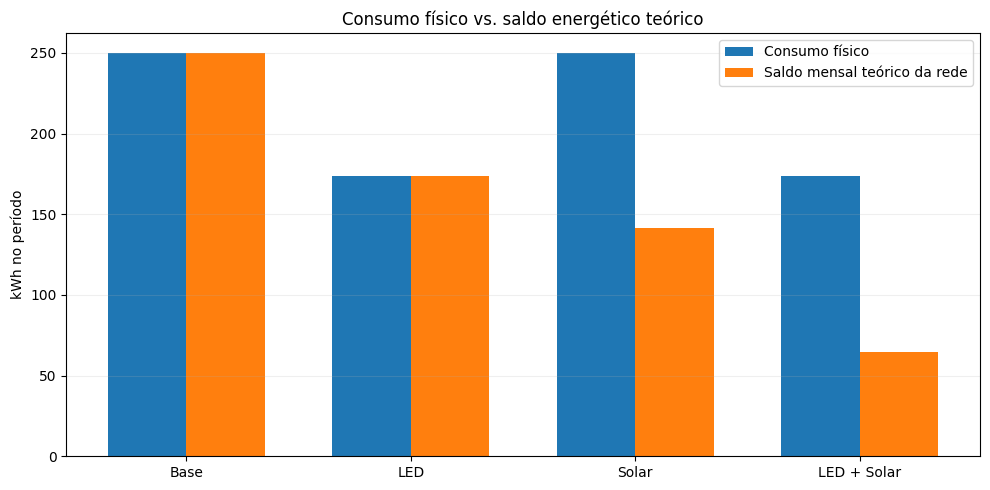

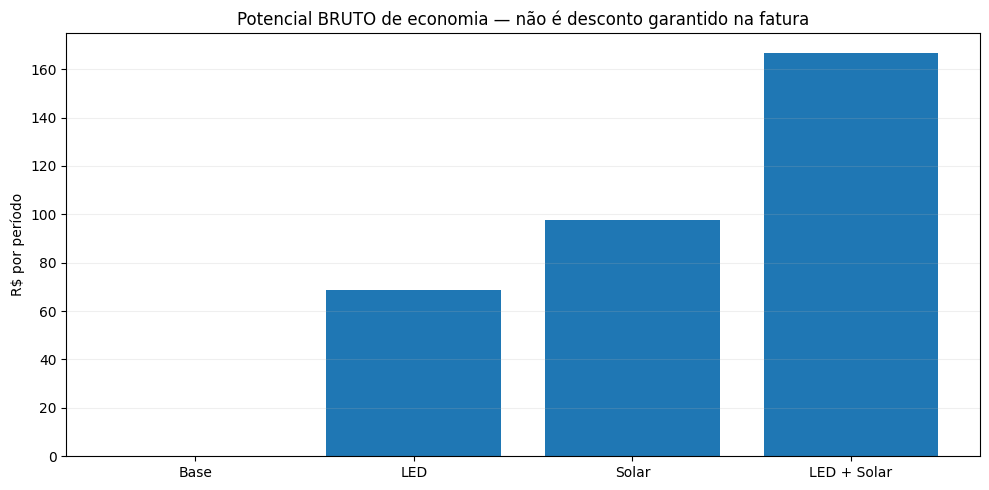

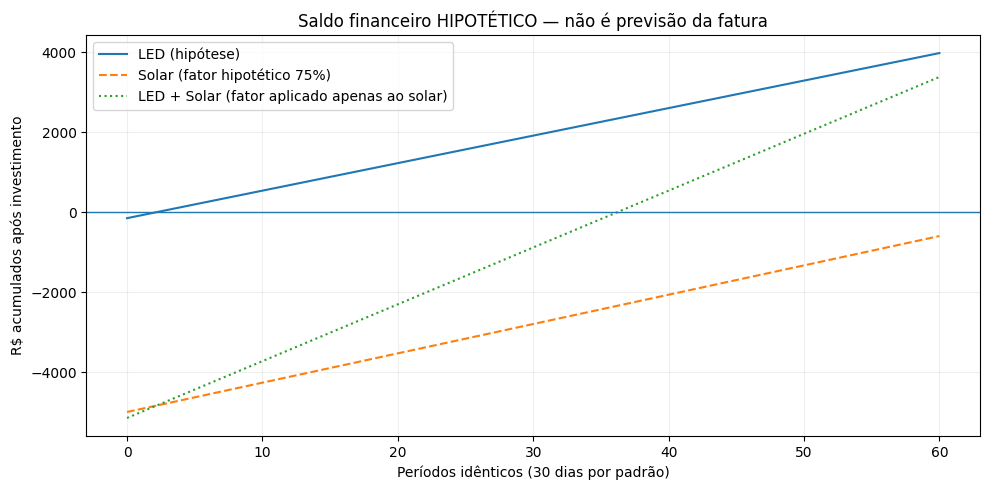

In [5]:
fig,ax=plt.subplots(figsize=(10,5))
idx=list(range(len(tabela)))
largura=0.35
ax.bar([x-largura/2 for x in idx], tabela['Consumo físico (kWh)'], width=largura, label='Consumo físico')
ax.bar([x+largura/2 for x in idx], tabela['Saldo energético teórico (kWh)'], width=largura, label='Saldo mensal teórico da rede')
ax.set_xticks(idx,tabela['Cenário'])
ax.set_ylabel('kWh no período')
ax.set_title('Consumo físico vs. saldo energético teórico')
ax.legend()
ax.grid(axis='y', alpha=0.2)
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(10,5))
ax.bar(tabela['Cenário'],tabela['Economia bruta teórica (R$/período)'])
ax.set_title('Potencial BRUTO de economia — não é desconto garantido na fatura')
ax.set_ylabel('R$ por período')
ax.grid(axis='y',alpha=0.2)
plt.tight_layout();plt.show()

periodos = list(range(0,61)) # 0 a 60 períodos idênticos (30 dias por padrão)
linha_led = tabela.set_index('Cenário').loc['LED']
linha_solar = tabela.set_index('Cenário').loc['Solar']
linha_ambas = tabela.set_index('Cenário').loc['LED + Solar']
fator = parametros['aproveitamento_financeiro']
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(periodos, [t*linha_led['Economia ajustada (R$/período; hipótese)']-linha_led['Investimento hipotético (R$)'] for t in periodos], label='LED (hipótese)')
ax.plot(periodos, [t*linha_solar['Economia ajustada (R$/período; hipótese)']-linha_solar['Investimento hipotético (R$)'] for t in periodos], linestyle='--',label=f'Solar (fator hipotético {fator:.0%})')
ax.plot(periodos, [t*linha_ambas['Economia ajustada (R$/período; hipótese)']-linha_ambas['Investimento hipotético (R$)'] for t in periodos], linestyle=':',label='LED + Solar (fator aplicado apenas ao solar)')
ax.axhline(0, linewidth=1)
ax.set_title('Saldo financeiro HIPOTÉTICO — não é previsão da fatura')
ax.set_xlabel('Períodos idênticos (30 dias por padrão)')
ax.set_ylabel('R$ acumulados após investimento')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout();plt.show()

## 7. Viabilidade, impacto ambiental e fontes dos dados

O **fator financeiro solar** representa uma hipótese arbitrária sobre a fração do potencial bruto capturada economicamente; não reproduz qualquer regra da ANEEL. A tabela mostra cenários de 50%, 75% e 100% **apenas para demonstrar como o retorno muda**. Para uma análise comercial real seriam necessários perfil horário, tarifa detalhada, regras da distribuidora, condições de instalação e orçamento.

Para emissões, usa-se o fator médio histórico de inventários do SIN (2023). O produto `kWh × fator` é uma **aproximação contábil** e não deve ser chamado de toneladas de emissões efetivamente evitadas ou certificadas; painel solar também tem impactos de fabricação, transporte e descarte.

In [6]:
ganho_solar_bruto = float(linha_solar['Economia bruta teórica (R$/período)'])
linhas_sensibilidade = []
for fracao in [0.50,0.75,1.00]:
    ganho = ganho_solar_bruto*fracao
    linhas_sensibilidade.append({
        'Fração hipotética do ganho bruto':f'{fracao:.0%}',
        'Ganho solar no cenário (R$/período)':ganho,
        'Retorno ilustrativo (períodos)':retorno_simples(parametros['custo_solar'],ganho)
    })
display(pd.DataFrame(linhas_sensibilidade).round(2).fillna('não retorna'))
fontes_dos_parametros = pd.DataFrame([
    ['Consumo e tarifa','informação digitada no formulário','hipótese inicial — consultar fatura real para caso aplicado'],
    ['Potência, fluxo luminoso e custo das lâmpadas','informação digitada no formulário','hipótese inicial — conferir embalagem/registro Inmetro'],
    ['Tamanho, custo e desempenho FV','informação digitada no formulário','hipótese inicial — conferir orçamento e restrições do imóvel'],
    ['HSP',resultado['origem_hsp'],resultado['url_nasa'] or 'hipótese informada pelo usuário'],
    ['Fator médio de CO₂',f"{parametros['co2']} kg CO₂/kWh",'MCTI/SIRENE, ano 2023 para valor padrão; substituir se alterado'],
], columns=['Dado','Valor/origem','Nota metodológica'])
display(fontes_dos_parametros)
print('Limites de viabilidade: área e orientação do telhado, sombreamento, localidade, vida útil, custo de manutenção, fluxo luminoso e regras de compensação.')

,Fração hipotética do ganho bruto,Ganho solar no cenário (R$/período),Retorno ilustrativo (períodos)
0,50%,48.91,102.23
1,75%,73.37,68.15
2,100%,97.82,51.11


,Dado,Valor/origem,Nota metodológica
0,Consumo e tarifa,informação digitada no formulário,hipótese inicial — consultar fatura real para ...
1,"Potência, fluxo luminoso e custo das lâmpadas",informação digitada no formulário,hipótese inicial — conferir embalagem/registro...
2,"Tamanho, custo e desempenho FV",informação digitada no formulário,hipótese inicial — conferir orçamento e restri...
3,HSP,"NASA POWER, climatologia histórica da irradiaç...",https://power.larc.nasa.gov/api/temporal/clima...
4,Fator médio de CO₂,0.0385 kg CO₂/kWh,"MCTI/SIRENE, ano 2023 para valor padrão; subst..."


Limites de viabilidade: área e orientação do telhado, sombreamento, localidade, vida útil, custo de manutenção, fluxo luminoso e regras de compensação.


## 8. Assistente EnergiaClara AI — perguntas sobre a simulação

O assistente é **determinístico, com interpretação de palavras-chave**, não é IA generativa e não inventa dados externos. Ele responde aos resultados produzidos acima e informa quando não consegue interpretar a pergunta. Troque o texto do campo e execute **apenas a célula abaixo** para outra resposta; se mudar números no formulário, execute primeiro todas as células desde o formulário.
**Melhoria do notebook:** a resposta será apresentada em itens com títulos e uma observação sobre as limitações. A lógica e os cálculos de `responder()` permanecem os mesmos, para preservar os testes.


In [7]:
#@title 8. Pergunte ao EnergiaClara AI — edite e execute
pergunta = "Qual alternativa compensa mais para minha casa?" #@param {type:"string"}

def normalizar(texto):
    return ''.join(c for c in unicodedata.normalize('NFKD',texto.lower()) if not unicodedata.combining(c))

def responder(pergunta, r):
    if not pergunta.strip():
        return 'Digite uma pergunta sobre consumo, LED, energia solar, investimento, retorno, CO₂, fontes ou limitações.'
    texto=normalizar(pergunta)
    tab=r['df'].set_index('Cenário'); p=r['p']
    led=tab.loc['LED']; solar=tab.loc['Solar']; ambas=tab.loc['LED + Solar']
    led_rs=led['Economia bruta teórica (R$/período)']
    solar_rs=solar['Economia bruta teórica (R$/período)']
    ganho_led_ajustado=led['Economia ajustada (R$/período; hipótese)']
    ganho_solar_ajustado=solar['Economia ajustada (R$/período; hipótese)']
    pb_led=retorno_simples(p['custo_led'],ganho_led_ajustado)
    pb_solar=retorno_simples(p['custo_solar'],ganho_solar_ajustado)
    fmt=lambda x: 'não calculável (economia zero)' if x is None else f'{x:.1f} períodos'
    aviso='A economia financeira solar é um cenário hipotético de potencial bruto; regras de compensação e custos não foram simulados.'
    if any(pal in texto for pal in ['compensa','melhor','vale a pena','recomenda','escolher','vantagem']):
        return (f'Com os parâmetros atuais, LED reduz {r["led_kwh"]:.1f} kWh de consumo por período e custa R$ {p["custo_led"]:.2f} de investimento; retorno BRUTO simples: {fmt(pb_led)}. '
                f'Solar gera aproximadamente {r["fv"]:.1f} kWh por período e custa R$ {p["custo_solar"]:.2f}; retorno simples com fator financeiro HIPOTÉTICO de {p["aproveitamento_financeiro"]:.0%}: {fmt(pb_solar)}. '
                'Para começar com menor investimento, LED tende a ser mais acessível neste exemplo; solar exige orçamento e estudo do imóvel. ' + aviso)
    if any(pal in texto for pal in ['retorno','payback','recuperar','tempo de volta']):
        return (f'Retorno simples ilustrativo: LED = {fmt(pb_led)}, Solar = {fmt(pb_solar)} com fator financeiro solar de {p["aproveitamento_financeiro"]:.0%}. '
                'Esses retornos não consideram manutenção, financiamento, tarifa real nem compensação de geração. ' + aviso)
    if any(pal in texto for pal in ['lampada','led','iluminacao','lumens']):
        return (f'A troca de {p["n"]} lâmpadas reduz {r["led_kwh"]:.1f} kWh no período, com economia bruta de R$ {led_rs:.2f}. '
                f'Confira fluxo luminoso: antiga {p["lm_antiga"]:.0f} lm; LED {p["lm_led"]:.0f} lm por lâmpada. '
                'Maior eficiência não dispensa verificar se há luminosidade adequada para o ambiente.')
    if any(pal in texto for pal in ['emiss','carbono','co2','ambient','sustent']):
        return (f'Indicador contábil ilustrativo: LED {led["Indicador CO₂ (kg/período; contábil)"]:.2f} kg CO₂; '
                f'Solar {solar["Indicador CO₂ (kg/período; contábil)"]:.2f} kg CO₂; '
                f'LED + Solar {ambas["Indicador CO₂ (kg/período; contábil)"]:.2f} kg CO₂ por período, usando {p["co2"]:.4f} kg/kWh. '
                'Este fator médio histórico não comprova emissões evitadas e não inclui ciclo de vida dos painéis.')
    if any(pal in texto for pal in ['limita','confiavel','garantia','precisao','exat']):
        return ('É um simulador educativo, sem histórico horário de consumo, tarifa completa, '
                'regulamentação de créditos na fatura, sazonalidade, custos operacionais ou avaliação do imóvel. ' + aviso)
    if ('solar' in texto or 'fotovolta' in texto or re.search(r'\b(placa|placas|painel|paineis|sol)\b',texto)):
        return (f'Sistema de {p["kwp"]:.2f} kWp: geração estimada de {r["fv"]:.1f} kWh por período, usando HSP de {r["hsp"]:.2f} e PR={p["pr"]:.2f}. '
                f'Origem da HSP: {r["origem_hsp"]}. {aviso}')
    if any(pal in texto for pal in ['invest','custo','preco','gasto','valor']):
        return (f'Investimentos hipotéticos: LED R$ {p["custo_led"]:.2f}, solar R$ {p["custo_solar"]:.2f}, ambos R$ {p["custo_led"]+p["custo_solar"]:.2f}. '
                f'Custo de energia base teórico: R$ {r["custo_base"]:.2f} por período. ' + aviso)
    if any(pal in texto for pal in ['consumo','kwh','economia','economizar','conta']):
        return (f'Consumo residencial inicial: {p["consumo"]:.1f} kWh em {p["dias"]} dias. '
                f'Com LED: {r["consumo_led"]:.1f} kWh físicos; com solar, o consumo físico NÃO muda. '
                f'Com LED + Solar, saldo mensal energético hipotético: {ambas["Saldo energético teórico (kWh)"]:.1f} kWh. ' + aviso)
    if any(pal in texto for pal in ['fonte','refer','nasa','aneel','inmetro','dados']):
        return (f'Parâmetros domésticos foram informados manualmente; HSP: {r["origem_hsp"]}. '
                'Fontes de método: ANEEL (tarifas e geração distribuída), Inmetro (lumens e lm/W), NASA POWER (irradiação) e MCTI (fator de emissões de 2023). Veja os links na seção 1.')
    return ('Ainda não interpreto essa pergunta. Experimente: "Qual alternativa compensa mais?", '
            '"Qual o retorno do investimento?", "Quanto economiza o LED?", '
            '"Quanto gera o solar?", "Qual o impacto ambiental?" ou "Quais são as limitações?".')

# A lógica de decisão acima continua retornando texto plano para os testes automáticos.
# A camada de apresentação abaixo organiza a mesma resposta, sem alterar cálculos.
from IPython.display import Markdown
import html

def organizar_resposta_markdown(pergunta_texto, resposta_texto):
    pergunta_limpa = html.escape(str(pergunta_texto).replace('\n', ' ')).replace('`', "'")
    texto = normalizar(pergunta_texto)
    titulos = [
        (['compensa','melhor','vale a pena','recomenda','escolher','vantagem'], 'Comparação e recomendação'),
        (['retorno','payback','recuperar','tempo de volta'], 'Retorno do investimento'),
        (['lampada','led','iluminacao','lumens'], 'Economia com iluminação LED'),
        (['emiss','carbono','co2','ambient','sustent'], 'Impacto ambiental'),
        (['limita','confiavel','garantia','precisao','exat'], 'Limitações da simulação'),
        (['solar','fotovolta','painel','placa'], 'Geração solar fotovoltaica'),
        (['invest','custo','preco','gasto','valor'], 'Custos e investimentos'),
        (['consumo','kwh','economia','economizar','conta'], 'Consumo e economia'),
        (['fonte','refer','nasa','aneel','inmetro','dados'], 'Fontes e premissas'),
    ]
    titulo = next((nome for termos, nome in titulos if any(t in texto for t in termos)), 'Orientação do assistente')
    # Separação por fim de frase: nunca por ponto decimal (76.5, 0.80 etc.).
    frases = [frase.strip() for frase in re.split(r'(?<=\.)\s+(?=[A-ZÁÀÂÃÉÊÍÓÔÕÚÇ])', resposta_texto.strip()) if frase.strip()]
    if not frases:
        frases = [resposta_texto.strip()]
    avisos_inicio = ('a economia financeira solar', 'esses retornos', 'este fator médio',
                     'é um simulador educativo', 'maior eficiência não',
                     'regras de compensação', 'sem histórico', 'a consulta')
    principais, alertas = [], []
    for frase in frases:
        norm = normalizar(frase).lower()
        if norm.startswith(tuple(normalizar(x).lower() for x in avisos_inicio)):
            alertas.append(frase)
        else:
            principais.append(frase)
    linhas = [f'### {titulo}', f'**Pergunta:** {pergunta_limpa}', '', '**Resposta baseada na simulação**', '']
    linhas += [f'- {frase}' for frase in principais]
    if alertas:
        linhas += ['', '**Cuidados e limitações**', '']
        linhas += [f'- {frase}' for frase in alertas]
    linhas += ['', '> **Importante:** os valores dependem dos parâmetros informados. A estimativa solar não é previsão da fatura real nem garantia de economia.']
    return '\n'.join(linhas)

resposta_atual = responder(pergunta, resultado)
display(Markdown(organizar_resposta_markdown(pergunta, resposta_atual)))

### Comparação e recomendação
**Pergunta:** Qual alternativa compensa mais para minha casa?

**Resposta baseada na simulação**

- Com os parâmetros atuais, LED reduz 76.5 kWh de consumo por período e custa R$ 150.00 de investimento; retorno BRUTO simples: 2.2 períodos.
- Solar gera aproximadamente 108.7 kWh por período e custa R$ 5000.00; retorno simples com fator financeiro HIPOTÉTICO de 75%: 68.2 períodos.
- Para começar com menor investimento, LED tende a ser mais acessível neste exemplo; solar exige orçamento e estudo do imóvel.

**Cuidados e limitações**

- A economia financeira solar é um cenário hipotético de potencial bruto; regras de compensação e custos não foram simulados.

> **Importante:** os valores dependem dos parâmetros informados. A estimativa solar não é previsão da fatura real nem garantia de economia.

## 9. Verificações matemáticas automáticas

Os testes abaixo comprovam consistência **matemática** de cenários controlados, não a precisão de uma conta real. Os testes **com usuários reais** ainda serão coletados separadamente, como pede o professor.

In [8]:
# Caso padrão verificável: 10 lâmpadas 60 W -> 9 W, 5 h/dia por 30 dias
assert abs(energia_lampadas(60,10,5,30)-90.0)<1e-9
assert abs(energia_lampadas(9,10,5,30)-13.5)<1e-9
assert abs(geracao_solar(1.0,4.5,30,0.80)-108.0)<1e-9
padrao=dict(parametros)
padrao.update({'consumo':250.0,'tarifa':0.9,'dias':30,'n':10,'p_antiga':60.0,'p_led':9.0,
              'horas':5.0,'kwp':1.0,'pr':0.8,'hsp_manual':4.5,'fonte_hsp':'Manual (hipótese)'})
res_teste = calcular(padrao)
assert abs(res_teste['led_kwh']-76.5)<1e-9
assert abs(res_teste['fv']-108.0)<1e-9
assert abs(res_teste['df'].iloc[3]['Saldo energético teórico (kWh)']-65.5)<1e-9
sem_solar = dict(padrao,kwp=0.0)
assert abs(calcular(sem_solar)['fv'])<1e-9
sem_troca = dict(padrao,p_led=60.0)
assert abs(calcular(sem_troca)['led_kwh'])<1e-9
invalido = dict(padrao,consumo=10.0)
try:
    calcular(invalido)
    raise AssertionError('Entradas inconsistentes não foram rejeitadas')
except ValueError:
    pass
assert (res_teste['df']['Saldo energético teórico (kWh)']>=0).all()
assert all(math.isfinite(x) for x in res_teste['df']['Economia bruta teórica (R$/período)'])
assert abs(res_teste['df'].set_index('Cenário').loc['LED','Economia ajustada (R$/período; hipótese)']-68.85)<1e-9
assert abs(res_teste['df'].set_index('Cenário').loc['Solar','Economia ajustada (R$/período; hipótese)']-(108*0.9*padrao['aproveitamento_financeiro']))<1e-9
assert abs(res_teste['df'].set_index('Cenário').loc['LED + Solar','Economia ajustada (R$/período; hipótese)']-(76.5*0.9+108*0.9*padrao['aproveitamento_financeiro']))<1e-9
print('✅ Todas as verificações matemáticas e de consistência passaram.')

✅ Todas as verificações matemáticas e de consistência passaram.


## 10. Validação com cenários diferentes (reprodutível e sem internet)

Agora testamos o simulador com diferentes perfis de residência, sem alterar os parâmetros do formulário principal. Estes são **casos sintéticos**, criados para verificar o comportamento do algoritmo — **não representam famílias entrevistadas nem dados de contas reais**.

Os testes incluem: residência de baixo consumo, consumo elevado, nenhum investimento, geração acima do consumo e alteração da tarifa. A tabela e o gráfico são evidências de execução, mas não substituem testes com usuários.

**O que deve acontecer:** nenhum saldo energético teórico pode ser negativo; LED deve diminuir apenas o consumo físico; solar não deve modificar o consumo físico; com tarifa maior, a economia bruta teórica aumenta; ao reduzir o fator financeiro solar, a economia ajustada não pode subir.


,Caso,Consumo de entrada (kWh/30d),Tarifa (R$/kWh),Economia LED (kWh),Geração solar (kWh),Saldo LED + solar (kWh),Economia ajustada LED (R$),Economia ajustada solar (R$),Economia ajustada combinada (R$)
0,Referência,250.0,0.90,76.50,108.00,65.50,68.85,72.90,141.75
1,Baixo consumo,150.0,0.75,38.25,63.84,47.91,28.69,35.91,64.60
2,Alto consumo,480.0,1.10,107.10,244.80,128.10,117.81,201.96,319.77
3,Sem melhorias,250.0,0.90,0.00,0.00,250.00,0.00,0.00,0.00
4,Excedente FV,180.0,0.90,38.25,364.50,0.00,34.43,121.50,130.11


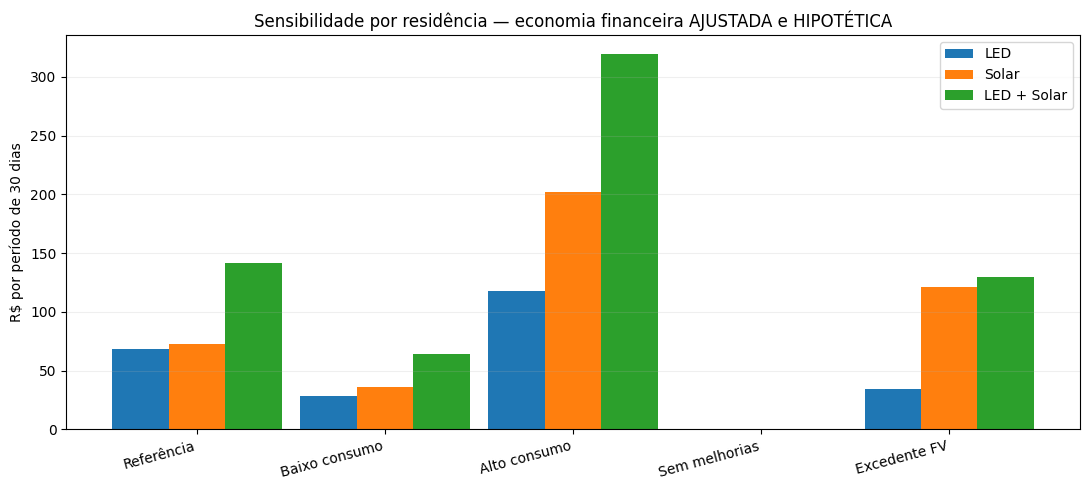

✅ 5 cenários sintéticos e verificações de extremos concluídos.


In [9]:
# Casos controlados; todos usam HSP manual para que a validação seja reproduzível.
# O formulário acima não é alterado.
base_teste = dict(padrao, fonte_hsp='Manual (hipótese)')
casos = {
    'Referência': dict(base_teste),
    'Baixo consumo': dict(base_teste, consumo=150.0, tarifa=0.75, n=5, kwp=0.7, hsp_manual=3.8, custo_led=80.0, custo_solar=3600.0),
    'Alto consumo': dict(base_teste, consumo=480.0, tarifa=1.10, n=14, kwp=2.0, hsp_manual=5.1, custo_led=220.0, custo_solar=9500.0),
    'Sem melhorias': dict(base_teste, n=0, kwp=0.0, custo_led=0.0, custo_solar=0.0),
    'Excedente FV': dict(base_teste, consumo=180.0, n=5, kwp=2.5, hsp_manual=5.4, pr=0.90, custo_solar=11500.0),
}
linhas_casos = []
for nome, p in casos.items():
    r = calcular(p)
    frame = r['df'].set_index('Cenário')
    led = frame.loc['LED']; sol = frame.loc['Solar']; ambas = frame.loc['LED + Solar']
    assert (frame['Saldo energético teórico (kWh)']>=0).all(), nome
    assert abs(sol['Consumo físico (kWh)'] - p['consumo']) < 1e-9, nome
    assert abs(led['Consumo físico (kWh)'] - (p['consumo']-r['led_kwh'])) < 1e-9, nome
    assert (frame['Economia ajustada (R$/período; hipótese)'] <= frame['Economia bruta teórica (R$/período)']+1e-9).all(), nome
    # Retorno (payback) indeterminado para economia zero é esperado; não é erro.
    linhas_casos.append({
        'Caso':nome, 'Consumo de entrada (kWh/30d)':p['consumo'], 'Tarifa (R$/kWh)':p['tarifa'],
        'Economia LED (kWh)':r['led_kwh'], 'Geração solar (kWh)':r['fv'],
        'Saldo LED + solar (kWh)':ambas['Saldo energético teórico (kWh)'],
        'Economia ajustada LED (R$)':led['Economia ajustada (R$/período; hipótese)'],
        'Economia ajustada solar (R$)':sol['Economia ajustada (R$/período; hipótese)'],
        'Economia ajustada combinada (R$)':ambas['Economia ajustada (R$/período; hipótese)'],
    })
# Consistência nos extremos, incluindo insumos inválidos.
sem_melhorias = calcular(casos['Sem melhorias'])['df'].set_index('Cenário')
assert (sem_melhorias['Economia bruta teórica (R$/período)'] == 0).all()
excedente = calcular(casos['Excedente FV'])['df'].set_index('Cenário')
assert excedente.loc['Solar','Saldo energético teórico (kWh)'] == 0
assert abs(excedente.loc['LED + Solar','Geração FV (kWh)'] - geracao_solar(2.5,5.4,30,.90)) < 1e-9

def deve_rejeitar(**alteracoes):
    try:
        calcular(dict(base_teste, **alteracoes))
    except ValueError:
        return True
    return False

assert deve_rejeitar(tarifa=-1)
assert deve_rejeitar(horas=25)
assert deve_rejeitar(p_led=80.0)
assert deve_rejeitar(consumo=20.0)
assert deve_rejeitar(hsp_manual=-2)
assert deve_rejeitar(aproveitamento_financeiro=1.5)

baixo_fator = calcular(dict(base_teste, aproveitamento_financeiro=0.25))['df'].set_index('Cenário')
alto_fator = calcular(dict(base_teste, aproveitamento_financeiro=0.95))['df'].set_index('Cenário')
assert baixo_fator.loc['Solar','Economia ajustada (R$/período; hipótese)'] < alto_fator.loc['Solar','Economia ajustada (R$/período; hipótese)']
assert abs(baixo_fator.loc['LED','Economia ajustada (R$/período; hipótese)']-alto_fator.loc['LED','Economia ajustada (R$/período; hipótese)'])<1e-9

comparativo_cenarios = pd.DataFrame(linhas_casos)
display(comparativo_cenarios.round(2))
fig, ax = plt.subplots(figsize=(11,5))
xs = range(len(comparativo_cenarios))
ax.bar([x-0.3 for x in xs],comparativo_cenarios['Economia ajustada LED (R$)'],width=0.3,label='LED')
ax.bar(xs,comparativo_cenarios['Economia ajustada solar (R$)'],width=0.3,label='Solar')
ax.bar([x+0.3 for x in xs],comparativo_cenarios['Economia ajustada combinada (R$)'],width=0.3,label='LED + Solar')
ax.set_xticks(list(xs),comparativo_cenarios['Caso'],rotation=15,ha='right')
ax.set_title('Sensibilidade por residência — economia financeira AJUSTADA e HIPOTÉTICA')
ax.set_ylabel('R$ por período de 30 dias')
ax.grid(axis='y',alpha=0.2)
ax.legend()
plt.tight_layout();plt.show()
print('✅ 5 cenários sintéticos e verificações de extremos concluídos.')


## 11. Evidências da análise e arquivos para o repositório

Esta célula produz arquivos de **dados simulados e auditáveis** para anexar ao GitHub depois, junto com o notebook. Ela inclui os parâmetros aplicados, os resultados atuais, a comparação entre cenários e a origem dos dados. Ao modificar o formulário, execute as células novamente antes de exportar.

**Não confundir:** exportação do notebook ≠ evidência de teste com usuários reais. Os resultados deste bloco são apenas cálculos. Em Colab, os arquivos aparecem na lateral em **Arquivos** e poderão ser baixados individualmente.


In [10]:
import json
from pathlib import Path
saida = Path('energiaclara_evidencias')
saida.mkdir(exist_ok=True)
resultado['df'].to_csv(saida/'resultado_atual.csv',index=False,encoding='utf-8-sig')
comparativo_cenarios.to_csv(saida/'cinco_cenarios_sinteticos.csv',index=False,encoding='utf-8-sig')
fontes_dos_parametros.to_csv(saida/'origens_parametros.csv',index=False,encoding='utf-8-sig')
registro = {
    'projeto':'EnergiaClara AI — Global Solution', 'versao':'v4',
    'natureza':'simulação educativa; entrada residencial hipotética ou fornecida pelo usuário',
    'periodo_dias':parametros['dias'],
    'parametros_formulario':parametros,
    'fonte_hsp_aplicada':resultado['origem_hsp'], 'valor_hsp':resultado['hsp'],
    'url_consulta_nasa':resultado['url_nasa'],
    'fontes_metodo':{
        'ANEEL_GD':'https://www.gov.br/aneel/pt-br/assuntos/geracao-distribuida',
        'ANEEL_tarifa':'https://www.gov.br/aneel/pt-br/assuntos/tarifas/entenda-a-tarifa/custo-da-energia-que-chega-aos-consumidores',
        'INMETRO_lampadas':'https://www.gov.br/inmetro/pt-br/acesso-a-informacao/perguntas-frequentes/avaliacao-da-conformidade/lampadas-e-luminarias-led-portaria-inmetro-no-231-2026-consumidores/para-pagar-uma-conta-de-energia-mais-barata-devo-comprar-lampadas-e-luminarias-de-luz-201cfria201d',
        'NASA_POWER':'https://power.larc.nasa.gov/docs/services/api/temporal/climatology/',
        'MCTI_CO2_2023':'https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/noticias/2024/02/fator-de-emissao-de-co2-na-geracao-de-energia-eletrica-no-brasil-em-2023-e-o-menor-em-12-anos',
    },
    'notas':['Fator financeiro solar é hipótese de sensibilidade; não representa compensação tarifária',
             'Fator CO2 2023 é histórico; não representa emissões evitadas verificadas',
             'Saldo de rede é cálculo energético teórico e não equivale à fatura real'],
}
with open(saida/'parametros_e_fontes.json','w',encoding='utf-8') as arq:
    json.dump(registro,arq,ensure_ascii=False,indent=2)
print('Arquivos da análise criados:')
for f in sorted(saida.iterdir()): print('  ',f)


Arquivos da análise criados:
   energiaclara_evidencias/cinco_cenarios_sinteticos.csv
   energiaclara_evidencias/origens_parametros.csv
   energiaclara_evidencias/parametros_e_fontes.json
   energiaclara_evidencias/resultado_atual.csv


## 12. Teste real de usabilidade e registro de melhoria

O enunciado pede **situações testadas, comentários recebidos e ajustes realizados**. O registro abaixo apresenta o relato real do participante anônimo **P1**, fornecido pelo responsável pelo projeto:

- Conseguiu utilizar o programa.
- Entendeu os gráficos e considerou o uso fácil.
- Sugeriu deixar as respostas do assistente mais organizadas.

**Ajuste realizado:** na seção 8, as respostas passaram a ter título, tópicos e destaque para limitações. O responsável pelo projeto aprovou visualmente a mudança. **Ainda não foi informado um novo teste de P1 após a melhoria.**

Você poderá registrar futuramente outro participante (P2 etc.) ou o reteste de P1. Marque um reteste como realizado **apenas se a pessoa realmente testou o layout revisado**; se marcar, descreva brevemente o que ela respondeu. O reteste é útil, mas o enunciado não fixa um número de repetições.

**Roteiro prático:** peça à pessoa para alterar o consumo, localizar a economia com LED, comparar com a geração solar, fazer uma pergunta ao assistente e identificar pelo menos uma limitação. Registre as respostas sem coletar nome completo, endereço ou número de conta.


In [11]:
#@title 12. Registro de usabilidade — dados do participante real P1
registrar_teste_real = True #@param {type:"boolean"}
participante_anonimo = "P1" #@param {type:"string"}
tarefa_testada = "Utilizar o simulador e interpretar gráficos e respostas" #@param {type:"string"}
compreendeu_resultados = "Sim" #@param ["Não avaliado", "Sim", "Parcialmente", "Não"]
feedback_recebido = "Conseguiu utilizar; entendeu os gráficos; achou fácil de usar; sugeriu organizar melhor as respostas do assistente." #@param {type:"string"}
ajuste_efetivamente_realizado = "Respostas da seção 8 reorganizadas em tópicos e com limitações em destaque." #@param {type:"string"}
reteste_da_melhoria = "Não realizado" #@param ["Não realizado", "Realizado — aprovado", "Realizado — precisa de ajustes"]
comentario_reteste = "" #@param {type:"string"}

colunas_usuarios = ['Participante anônimo', 'Tarefa', 'Compreensão', 'Comentário real',
                    'Ajuste efetivamente realizado', 'Reteste da melhoria', 'Comentário do reteste']
if 'registros_reais' not in globals():
    registros_reais=[]
if registrar_teste_real:
    if not participante_anonimo.strip() or not feedback_recebido.strip() or compreendeu_resultados=='Não avaliado':
        raise ValueError('Informe identificador anônimo, compreensão e relato verdadeiro do participante.')
    if reteste_da_melhoria!='Não realizado' and not comentario_reteste.strip():
        raise ValueError('Se a melhoria foi retestada, informe o comentário real recebido após o reteste.')
    registro_real = dict(zip(colunas_usuarios,[participante_anonimo,tarefa_testada,compreendeu_resultados,
          feedback_recebido,ajuste_efetivamente_realizado,reteste_da_melhoria,comentario_reteste]))
    registros_reais=[r for r in registros_reais if not (r.get('Participante anônimo')==participante_anonimo and r.get('Tarefa')==tarefa_testada)]
    registros_reais.append(registro_real)
    print('Registro de participante real salvo; o status do reteste reflete somente o que você declarou.')
else:
    print('Registro desativado nesta execução; nenhum registro novo será criado.')

tabela_usuarios=pd.DataFrame(registros_reais,columns=colunas_usuarios)
saida.mkdir(exist_ok=True)
arquivo_teste=saida/'testes_usuarios_reais.csv'
tabela_usuarios.to_csv(arquivo_teste,index=False,encoding='utf-8-sig')
display(tabela_usuarios)
print('Arquivo de relato (sem participantes inventados):',arquivo_teste)


Registro de participante real salvo; o status do reteste reflete somente o que você declarou.


,Participante anônimo,Tarefa,Compreensão,Comentário real,Ajuste efetivamente realizado,Reteste da melhoria,Comentário do reteste
0,P1,Utilizar o simulador e interpretar gráficos e ...,Sim,Conseguiu utilizar; entendeu os gráficos; acho...,Respostas da seção 8 reorganizadas em tópicos ...,Não realizado,


Arquivo de relato (sem participantes inventados): energiaclara_evidencias/testes_usuarios_reais.csv


## 13. Proveniência dos dados — valores variáveis e evidências verificáveis

Os valores numéricos do formulário são editáveis e, inicialmente, **hipóteses didáticas**. Mesmo quando a fórmula está correta, o resultado só pode ser aplicado a uma residência real se as entradas forem verificadas. Aqui registramos **de onde vieram** os dados, quando foram consultados e quais pontos ainda são estimativas.

**Como coletar, sem expor dados pessoais:**

- **Consumo:** copiar somente o total de kWh de uma fatura própria; não anexar nome, CPF, endereço, instalação ou número da conta.
- **Tarifa:** preferir preço aproximado por kWh obtido da fatura do próprio usuário; alternativa: consultar tarifa **TE + TUSD** da distribuidora no [portal da ANEEL](https://dadosabertos.aneel.gov.br/dataset/tarifas-distribuidoras-energia-eletrica). Não confundir tarifa homologada sem tributos com o preço final da conta.
- **LED:** escolher um modelo real, registrar sua potência, seus lúmens e sua data/preço; verificar informações no [Sistema PBE/Inmetro](https://www.gov.br/inmetro/pt-br/assuntos/regulamentacao/avaliacao-da-conformidade/programa-brasileiro-de-etiquetagem/tabelas-de-eficiencia-energetica/lampadas).
- **Solar:** o custo depende do porte, telhado, equipamentos, projeto e instalação. Preferir **cotação datada**, em vez de extrapolar valores de portes diferentes.
- **Irradiação:** selecionar NASA POWER na seção 3 para usar climatologia histórica (quando houver internet), ou usar HSP manual **explicitamente identificada**.

**Regra metodológica:** uma referência publicada não transforma uma hipótese digitada em dado coletado. Preencha a classificação e a origem abaixo só após conferir cada valor.

In [12]:
#@title 13. Ficha de evidências — registre as origens (não inclua dados pessoais)
classificacao_consumo = "Hipótese didática" #@param ["Hipótese didática", "Consumo de fatura consultada", "Dado público verificado"]
classificacao_tarifa = "Hipótese didática" #@param ["Hipótese didática", "Valor aproximado de fatura", "Tarifa ANEEL sem tributos"]
classificacao_led = "Hipótese didática" #@param ["Hipótese didática", "Modelo e preço verificados"]
classificacao_solar = "Hipótese didática" #@param ["Hipótese didática", "Orçamento formal consultado"]
modelo_led = "Não identificado" #@param {type:"string"}
distribuidora_eletrica = "Não identificada" #@param {type:"string"}
referencia_tarifa_url = "" #@param {type:"string"}
referencia_consumo_url = "" #@param {type:"string"}
referencia_led_url = "" #@param {type:"string"}
referencia_solar_url = "" #@param {type:"string"}
consulta_em = "2026-11-13" #@param {type:"date"}
observacoes_fontes = "Dados iniciais ilustrativos; nenhuma fatura, produto ou cotação comprovado ainda." #@param {type:"string"}

from datetime import date
try:
    data_evidencia = date.fromisoformat(str(consulta_em))
except ValueError as exc:
    raise ValueError('Use uma data de consulta válida no formato AAAA-MM-DD.') from exc

registro_fontes = [
    {'Variável':'Consumo (kWh)', 'Valor':round(parametros['consumo'],3), 'Unidade':'kWh/período',
     'Classificação':classificacao_consumo, 'Origem': 'Informação pessoal não anexada' if classificacao_consumo=='Consumo de fatura consultada' else referencia_consumo_url if classificacao_consumo=='Dado público verificado' else 'Formulário hipotético'},
    {'Variável':'Tarifa aproximada', 'Valor':parametros['tarifa'],'Unidade':'R$/kWh',
     'Classificação':classificacao_tarifa,'Origem':referencia_tarifa_url if classificacao_tarifa=='Tarifa ANEEL sem tributos' else 'Fatura sem dados identificáveis' if classificacao_tarifa=='Valor aproximado de fatura' else 'Formulário hipotético'},
    {'Variável':'LED (potência/lúmens)', 'Valor':f"{parametros['p_led']:g} W / {parametros['lm_led']:g} lm", 'Unidade':'por lâmpada',
     'Classificação':classificacao_led,'Origem':referencia_led_url if classificacao_led!='Hipótese didática' else 'Formulário hipotético'},
    {'Variável':'Investimento LED', 'Valor':parametros['custo_led'], 'Unidade':'R$ (total)',
     'Classificação':classificacao_led,'Origem':referencia_led_url if classificacao_led!='Hipótese didática' else 'Formulário hipotético'},
    {'Variável':'Investimento solar', 'Valor':parametros['custo_solar'], 'Unidade':'R$ (total)',
     'Classificação':classificacao_solar,'Origem':referencia_solar_url if classificacao_solar!='Hipótese didática' else 'Formulário hipotético'},
    {'Variável':'Irradiação/HSP', 'Valor':round(resultado['hsp'],3), 'Unidade':'kWh/m²/dia (referência horizontal)',
     'Classificação':'NASA POWER — climatologia histórica' if resultado['url_nasa'] else 'Hipótese manual',
     'Origem':resultado['url_nasa'] or 'Formulário hipotético'},
    {'Variável':'Fator CO₂', 'Valor':parametros['co2'], 'Unidade':'kg CO₂/kWh',
     'Classificação':'Histórico MCTI 2023' if abs(parametros['co2']-.0385)<1e-10 else 'Fator alterado; fonte precisa ser informada',
     'Origem':'https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/noticias/2024/02/fator-de-emissao-de-co2-na-geracao-de-energia-eletrica-no-brasil-em-2023-e-o-menor-em-12-anos' if abs(parametros['co2']-.0385)<1e-10 else observacoes_fontes}
]
evidencias_v4 = pd.DataFrame(registro_fontes)
evidencias_v4['Consultado em'] = str(data_evidencia)
display(evidencias_v4)
alertas_evidencias = []
if classificacao_tarifa=='Tarifa ANEEL sem tributos' and not referencia_tarifa_url.startswith('https://'):
    alertas_evidencias.append('Tarifa ANEEL declarada, mas falta o URL exato da consulta.')
if classificacao_led=='Modelo e preço verificados' and (not referencia_led_url.startswith('https://') or modelo_led=='Não identificado'):
    alertas_evidencias.append('LED declarado como verificado, mas falta o modelo ou o endereço da evidência.')
if classificacao_solar=='Orçamento formal consultado' and not (referencia_solar_url.strip() or observacoes_fontes.strip()):
    alertas_evidencias.append('Solar declarado como orçamento, mas falta uma referência de documentação.')
if classificacao_consumo=='Dado público verificado' and not referencia_consumo_url.startswith('https://'):
    alertas_evidencias.append('Consumo público declarado, mas falta URL específico em referencia_consumo_url.')
if not alertas_evidencias:
    print('Ficha processada. Verifique se a classificação corresponde à documentação realmente consultada.')
else:
    for aviso in alertas_evidencias:
        print('⚠',aviso)
print('Atenção: os parâmetros utilizados nos cálculos continuam sendo os da seção 3; esta ficha documenta a procedência, sem alterá-los.')

,Variável,Valor,Unidade,Classificação,Origem,Consultado em
0,Consumo (kWh),250.0,kWh/período,Hipótese didática,Formulário hipotético,2026-11-13
1,Tarifa aproximada,0.9,R$/kWh,Hipótese didática,Formulário hipotético,2026-11-13
2,LED (potência/lúmens),9 W / 800 lm,por lâmpada,Hipótese didática,Formulário hipotético,2026-11-13
3,Investimento LED,150.0,R$ (total),Hipótese didática,Formulário hipotético,2026-11-13
4,Investimento solar,5000.0,R$ (total),Hipótese didática,Formulário hipotético,2026-11-13
5,Irradiação/HSP,4.529,kWh/m²/dia (referência horizontal),NASA POWER — climatologia histórica,https://power.larc.nasa.gov/api/temporal/clima...,2026-11-13
6,Fator CO₂,0.0385,kg CO₂/kWh,Histórico MCTI 2023,https://www.gov.br/mcti/pt-br/acompanhe-o-mcti...,2026-11-13


Ficha processada. Verifique se a classificação corresponde à documentação realmente consultada.
Atenção: os parâmetros utilizados nos cálculos continuam sendo os da seção 3; esta ficha documenta a procedência, sem alterá-los.


### Referência de custos de sistemas solares — exemplo de pesquisa de mercado, não orçamento

Um levantamento setorial da **Greener**, para **junho de 2026**, foi divulgado por veículos especializados, informando referências médias de sistemas instalados de **2 kWp (R$ 3,62/Wp)** e **4 kWp (R$ 2,91/Wp)**. Trata-se de **referência setorial secundariamente reportada**, não de uma cotação da sua residência. Fontes para conferência: [Battery Channel — estudo de 2026](https://www.batterychannel.com.br/noticias/preco-medio-de-sistemas-solares-ate-300-kw-sobe-7-no-primeiro-semestre-no-brasil-cf6151a5) e [Solarprime — explicação da pesquisa](https://solarprime.com.br/preco-painel-solar-residencial-por-kwp/).

**Limitação crucial:** o formulário usa **1,0 kWp por padrão**. Não vamos usar o valor de R$/Wp de 2 kWp como se fosse uma cotação de um sistema de 1 kWp, pois custo unitário pode depender do tamanho. Para um exemplo empírico, altere o porte para **2,0 kWp** e o investimento para **R$ 7.240,00**, deixando explícitos a origem, a data e as limitações da média nacional; os demais parâmetros continuam sendo hipóteses, a menos que sejam verificados.

In [13]:
referencia_mercado_solar = pd.DataFrame([
    {'Data-base':'jun/2026', 'Porte (kWp)':2.0, 'Custo médio (R$/Wp)':3.62, 'Preço de referência (R$)':7240.0,
     'Natureza':'Média setorial divulgada em fonte secundária',
     'Fonte':'https://www.batterychannel.com.br/noticias/preco-medio-de-sistemas-solares-ate-300-kw-sobe-7-no-primeiro-semestre-no-brasil-cf6151a5'},
    {'Data-base':'jun/2026', 'Porte (kWp)':4.0, 'Custo médio (R$/Wp)':2.91, 'Preço de referência (R$)':11640.0,
     'Natureza':'Média setorial divulgada em fonte secundária',
     'Fonte':'https://solarprime.com.br/preco-painel-solar-residencial-por-kwp/'},
])
display(referencia_mercado_solar)
porte = parametros['kwp']
if any(abs(porte-k)<1e-9 for k in [2.0,4.0]):
    ref_preco = referencia_mercado_solar.loc[(referencia_mercado_solar['Porte (kWp)']-porte).abs()<1e-9,'Preço de referência (R$)'].iloc[0]
    print(f'Para {porte:g} kWp há uma referência nacional histórica de R$ {ref_preco:,.2f}; o seu investimento informado é R$ {parametros["custo_solar"]:,.2f}.')
else:
    print(f'Para {porte:g} kWp não há ponto equivalente nesta tabela; não extrapolamos preços de outros portes.')
print('Esta tabela é apenas uma comparação externa: não substitui o orçamento nem modifica a simulação.')

,Data-base,Porte (kWp),Custo médio (R$/Wp),Preço de referência (R$),Natureza,Fonte
0,jun/2026,2.0,3.62,7240.0,Média setorial divulgada em fonte secundária,https://www.batterychannel.com.br/noticias/pre...
1,jun/2026,4.0,2.91,11640.0,Média setorial divulgada em fonte secundária,https://solarprime.com.br/preco-painel-solar-r...


Para 1 kWp não há ponto equivalente nesta tabela; não extrapolamos preços de outros portes.
Esta tabela é apenas uma comparação externa: não substitui o orçamento nem modifica a simulação.


## 14. Sensibilidade: o que muda quando os parâmetros variam?

Os custos de energia e os recursos solares não são constantes entre residências, épocas e regiões. Para verificar a robustez da recomendação, simulamos, de maneira **didática e reproduzível**, variações de **−20%, 0%, +20%** na tarifa e na HSP, e hipóteses de **50%, 75% e 100%** no fator financeiro solar. O *payback* abaixo é somente um **quociente simplificado**; as curvas não consideram sazonalidade, manutenção, juros, degradação, financiamento nem regra tarifária específica.

As variações **não são intervalos de confiança**, nem estimativas de incerteza com validade estatística; são testes de sensibilidade definidos pelo grupo.

Total de combinações controladas: 27


,Tarifa relativa,HSP relativa,Fator solar financeiro,Tarifa (R$/kWh),HSP (kWh/m²/dia),Economia LED (R$/período),Economia solar (R$/período),Economia conjunta (R$/período),Retorno LED (períodos),Retorno solar (períodos)
0,0.8,0.8,0.50,0.72,3.62,55.08,31.30,86.38,2.72,159.73
1,0.8,0.8,0.75,0.72,3.62,55.08,46.95,102.03,2.72,106.49
2,0.8,0.8,1.00,0.72,3.62,55.08,62.61,117.69,2.72,79.86
3,0.8,1.0,0.50,0.72,4.53,55.08,39.13,94.21,2.72,127.78
4,0.8,1.0,0.75,0.72,4.53,55.08,58.69,113.77,2.72,85.19
5,0.8,1.0,1.00,0.72,4.53,55.08,78.26,133.34,2.72,63.89
6,0.8,1.2,0.50,0.72,5.43,55.08,46.95,102.03,2.72,106.49
7,0.8,1.2,0.75,0.72,5.43,55.08,70.43,125.51,2.72,70.99
8,0.8,1.2,1.00,0.72,5.43,55.08,93.91,148.99,2.72,53.24


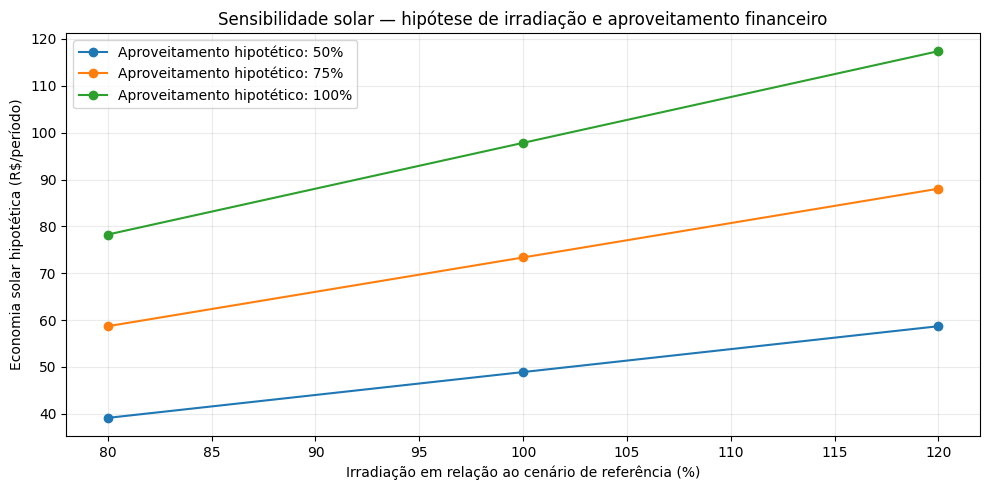

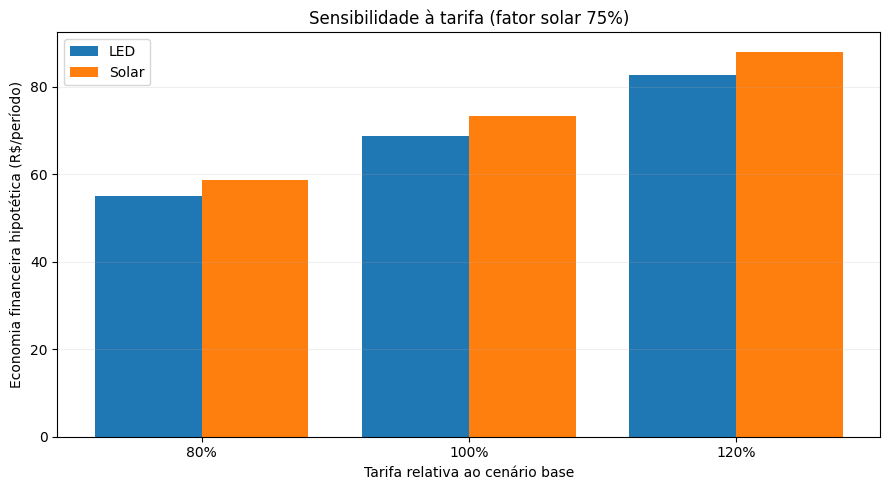

Interpretação: o cenário pode mudar conforme consumo, irradiação, tarifa e investimento. Esses dados não provam economia contratual na fatura.


In [14]:
from itertools import product
fatores_tarifa = [0.8,1.0,1.2]
fatores_hsp = [0.8,1.0,1.2]
hipoteses_financeiras = [0.50,0.75,1.00]
linhas_v4=[]
for ft,fh,fa in product(fatores_tarifa,fatores_hsp,hipoteses_financeiras):
    ptmp=dict(parametros,tarifa=parametros['tarifa']*ft,aproveitamento_financeiro=fa)
    sim=calcular(ptmp,hsp=min(12.0, resultado['hsp']*fh))
    tab=sim['df'].set_index('Cenário')
    linhas_v4.append({
        'Tarifa relativa':ft,'HSP relativa':fh,'Fator solar financeiro':fa,
        'Tarifa (R$/kWh)':ptmp['tarifa'],'HSP (kWh/m²/dia)':min(12.0,resultado['hsp']*fh),
        'Economia LED (R$/período)':tab.loc['LED','Economia ajustada (R$/período; hipótese)'],
        'Economia solar (R$/período)':tab.loc['Solar','Economia ajustada (R$/período; hipótese)'],
        'Economia conjunta (R$/período)':tab.loc['LED + Solar','Economia ajustada (R$/período; hipótese)'],
        'Retorno LED (períodos)':tab.loc['LED','Retorno simples AJUSTADO (períodos)'],
        'Retorno solar (períodos)':tab.loc['Solar','Retorno simples AJUSTADO (períodos)'],
    })
sensibilidade_v4 = pd.DataFrame(linhas_v4)
print('Total de combinações controladas:',len(sensibilidade_v4))
display(sensibilidade_v4.head(9).round(2).fillna('indeterminado'))
assert len(sensibilidade_v4)==27
assert (sensibilidade_v4['Economia solar (R$/período)']>=0).all()
assert (sensibilidade_v4['Economia conjunta (R$/período)']>=sensibilidade_v4['Economia LED (R$/período)']-1e-8).all()

fig,ax=plt.subplots(figsize=(10,5))
for fator_fin in hipoteses_financeiras:
    sub=sensibilidade_v4[(sensibilidade_v4['Tarifa relativa']==1.0)&(sensibilidade_v4['Fator solar financeiro']==fator_fin)].sort_values('HSP relativa')
    ax.plot(sub['HSP relativa']*100,sub['Economia solar (R$/período)'],marker='o',label=f'Aproveitamento hipotético: {fator_fin:.0%}')
ax.set_xlabel('Irradiação em relação ao cenário de referência (%)')
ax.set_ylabel('Economia solar hipotética (R$/período)')
ax.set_title('Sensibilidade solar — hipótese de irradiação e aproveitamento financeiro')
ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(9,5))
base_fa = min(hipoteses_financeiras, key=lambda x:abs(x-parametros['aproveitamento_financeiro']))
comparar=sensibilidade_v4[(sensibilidade_v4['HSP relativa']==1.0)&(sensibilidade_v4['Fator solar financeiro']==base_fa)].sort_values('Tarifa relativa')
xx=range(len(comparar))
ax.bar([x-.2 for x in xx],comparar['Economia LED (R$/período)'],width=.4,label='LED')
ax.bar([x+.2 for x in xx],comparar['Economia solar (R$/período)'],width=.4,label='Solar')
ax.set_xticks(list(xx),[f'{int(t*100)}%' for t in comparar['Tarifa relativa']])
ax.set_xlabel('Tarifa relativa ao cenário base')
ax.set_ylabel('Economia financeira hipotética (R$/período)')
ax.set_title(f'Sensibilidade à tarifa (fator solar {base_fa:.0%})')
ax.grid(axis='y',alpha=.2);ax.legend();plt.tight_layout();plt.show()
print('Interpretação: o cenário pode mudar conforme consumo, irradiação, tarifa e investimento. Esses dados não provam economia contratual na fatura.')

## 15. Testes do assistente e coerência das recomendações

Os **sete testes textuais** verificam temas e retornos previstos, mas não garantem compreensão linguística. A v6 preserva as verificações adicionais da v5: também executa testes numéricos e de cenários-limite na seção 19. Além dos testes matemáticos e dos cinco cenários sintéticos, validamos que o assistente **responde** às perguntas previstas sobre o cenário atual e informa limites. Esses testes verificam **retorno de texto e temas**, não a compreensão linguística completa de uma IA generativa. Os testes com pessoas reais continuam registrados separadamente na seção 12.

In [15]:
perguntas_de_teste = [
    ('Qual alternativa compensa mais?', ['LED','Solar']),
    ('Qual o retorno do investimento?', ['Retorno','Solar']),
    ('Quanto economizo com lâmpadas LED?', ['lâmpadas','kWh']),
    ('Como funciona o sistema solar?', ['kWp','HSP']),
    ('Qual o impacto de CO2?', ['CO₂']),
    ('Quais as limitações?', ['simulador']),
    ('Qual o investimento inicial?', ['R$']),
]
linhas_assistente=[]
for pergunta_teste,termos in perguntas_de_teste:
    resposta_teste=responder(pergunta_teste,resultado)
    passou=bool(isinstance(resposta_teste,str) and resposta_teste.strip() and all(t.casefold() in resposta_teste.casefold() for t in termos))
    linhas_assistente.append({'Pergunta':pergunta_teste,'Termos esperados':', '.join(termos),'Resultado':'OK' if passou else 'REVISAR', 'Trecho':resposta_teste[:110]})
    assert passou, f'Falha de teste do assistente: {pergunta_teste} -> {resposta_teste}'
testes_assistente_v4=pd.DataFrame(linhas_assistente)
display(testes_assistente_v4)
print(f'✅ {len(testes_assistente_v4)} perguntas previstas respondidas conforme a checagem automática.')
print('⚠ A avaliação automática não substitui os testes de compreensão com usuários reais.')
print('STATUS DA SEÇÃO 15: APROVADA — 7 de 7 verificações textuais.' if (testes_assistente_v4['Resultado']=='OK').all() else 'STATUS DA SEÇÃO 15: REVISAR checagens.')


,Pergunta,Termos esperados,Resultado,Trecho
0,Qual alternativa compensa mais?,"LED, Solar",OK,"Com os parâmetros atuais, LED reduz 76.5 kWh d..."
1,Qual o retorno do investimento?,"Retorno, Solar",OK,Retorno simples ilustrativo: LED = 2.2 período...
2,Quanto economizo com lâmpadas LED?,"lâmpadas, kWh",OK,A troca de 10 lâmpadas reduz 76.5 kWh no perío...
3,Como funciona o sistema solar?,"kWp, HSP",OK,Sistema de 1.00 kWp: geração estimada de 108.7...
4,Qual o impacto de CO2?,CO₂,OK,Indicador contábil ilustrativo: LED 2.95 kg CO...
5,Quais as limitações?,simulador,OK,"É um simulador educativo, sem histórico horári..."
6,Qual o investimento inicial?,R$,OK,"Investimentos hipotéticos: LED R$ 150.00, sola..."


✅ 7 perguntas previstas respondidas conforme a checagem automática.
⚠ A avaliação automática não substitui os testes de compreensão com usuários reais.
STATUS DA SEÇÃO 15: APROVADA — 7 de 7 verificações textuais.


## 16. Dados intermediários e referências (CSV; exportação final na seção 22)

A próxima célula exporta os arquivos da versão intermediária (mantida para compatibilidade) para uma pasta e um único `.zip`. O pacote contém entradas e origens, saídas, cenários sintéticos, sensibilidade, testes automatizados, referências de preços e o CSV de testes reais (inicialmente **sem participantes**, até que o grupo faça os testes). Não gera nem simula entrevistas.

Para **continuar depois sem perder dados no Colab**: baixe o `.ipynb` atualizado e, se tiver coletado entrevistas, baixe também o `.zip` após executar o registro de testes. O armazenamento temporário do Colab pode ser apagado ao encerrar a sessão. **Não envie o zip como entrega final:** segundo o enunciado, o arquivo de envio será um `.txt` com links do GitHub e vídeo.
Na v6, a exportação final única fica na **seção 22**, evitando que o estudante confunda arquivos de versões anteriores.


In [16]:
import zipfile
from datetime import timezone
# Garantir que a pasta de exportação exista, inclusive em ambiente novo.
saida.mkdir(exist_ok=True)
evidencias_v4.to_csv(saida/'fontes_verificadas_ou_hipoteticas.csv',index=False,encoding='utf-8-sig')
referencia_mercado_solar.to_csv(saida/'referencias_mercado_solar_2026.csv',index=False,encoding='utf-8-sig')
sensibilidade_v4.to_csv(saida/'sensibilidade_27_combinacoes.csv',index=False,encoding='utf-8-sig')
testes_assistente_v4.to_csv(saida/'testes_automatizados_assistente.csv',index=False,encoding='utf-8-sig')
manifesto_v4={
 'projeto':'EnergiaClara AI', 'versao':'v4',
 'gerado_utc':datetime.now(timezone.utc).isoformat(),
 'periodo_dias':parametros['dias'],
 'parametros_digitados':parametros,
 'data_consulta_evidencias':str(data_evidencia),
 'ficha_origens':registro_fontes,
 'alertas_de_documentacao':alertas_evidencias,
 'analises':'Cenários sintéticos (5); sensibilidade (27 combinações); perguntas do assistente (7)',
 'testes_usuarios_reais_registrados':len(registros_reais),
 'observacoes': [
  'Preços de 1 kWp iniciais são hipóteses, não preços extraídos da média para 2 ou 4 kWp.',
  'Dados de mercado de junho/2026 são referências nacionais e não cotações individuais.',
  'Tarifa e custo não reproduzem a fatura regulatória real; fator financeiro é hipótese.',
  'Não compartilhar fatura elétrica com dados pessoais; não inventar testes de usabilidade.',
 ]
}
with open(saida/'manifesto_v4.json','w',encoding='utf-8') as f:
    json.dump(manifesto_v4,f,ensure_ascii=False,indent=2,default=str)

print('Dados intermediários gerados; o ZIP oficial desta execução será criado na seção 22.')


Dados intermediários gerados; o ZIP oficial desta execução será criado na seção 22.


## 17. Discussão crítica e conclusão

O **EnergiaClara AI**, construído como notebook autônomo de Python no Google Colab, compara duas alternativas aplicadas ao mesmo domicílio: (A) substituição de lâmpadas por LED, que reduz **consumo físico**, e (B) adoção de solar fotovoltaica, que produz **geração renovável**. O caso combinado também é analisado, descontando primeiro o LED para evitar dupla contagem.

**O que já é comprovável no notebook:** fórmulas, gráficos, resposta do assistente, cinco cenários sintéticos, testes de extremos, 27 combinações de sensibilidade, testes de perguntas e exportação auditável de parâmetros. Uma consulta bem-sucedida à NASA fornece **dado histórico de irradiação**, não geração fotovoltaica efetivamente medida.

**O que ainda precisa ser feito com dados externos ou pessoas:** registrar parâmetros efetivamente consultados (preço/etiqueta LED, tarifa ou fatura, cotação de solar para o porte escolhido) e ampliar, se possível, a avaliação com outros usuários. Um relato real (P1) já foi registrado e gerou a melhoria de apresentação do assistente no notebook; essa alteração ainda não foi reavaliada por P1. Não registrar dados inventados nem assumir que links oficiais, por si só, comprovem valores de mercado.

**Interpretação ambiental:** CO₂ calculado é indicador contábil baseado no fator histórico informado; não demonstra redução causal certificada nem contabiliza o ciclo de vida dos equipamentos. O cenário fotovoltaico não faz cálculo regulatório da fatura: faltam horários de consumo, impostos, custo de disponibilidade, compensação, características do telhado, manutenção e degradação dos painéis.

**Próximas fases, após concluir e validar o Colab:** (1) organizar GitHub e README com todas as fontes e evidências; (2) gravar vídeo não listado no YouTube, de **até 3 minutos**; (3) enviar apenas o `.txt` contendo nomes, RMs e os dois links.


## 18. Auditoria das entradas e referências — o que é real e o que é hipótese?

O professor exige dados de origem explicada. **Uma fórmula correta não converte uma entrada hipotética em dado real**. A tabela abaixo classifica cada campo da simulação e indica quais registros ainda estão faltando. Ela lê os formulários das seções **3 e 13**.

- **Consumo:** preferencialmente extraído de uma fatura sem compartilhar nome, número de instalação ou endereço. Alternativamente, declarar *cenário sintético*.
- **Tarifa:** preferencialmente obtida na distribuidora / ANEEL, com data e observação de que tarifas oficiais normalmente **não incluem a totalidade dos impostos e encargos**.
- **LED:** registrar modelo específico, potência, fluxo luminoso, preço unitário e fonte. Comparar **lúmens** para assegurar uma necessidade equivalente de iluminação.
- **Solar:** registrar custo total de um orçamento **para o porte escolhido**. Pesquisas setoriais de outros portes não devem ser extrapoladas automaticamente.
- **Irradiação:** se a NASA POWER responder, registrar a URL e o valor climatológico; caso contrário, HSP manual permanece hipótese.

Fontes metodológicas oficiais consultadas:

| Tema | Fonte | Papel |
|---|---|---|
| Tarifas | [ANEEL — tarifas](https://www.gov.br/aneel/pt-br/centrais-de-conteudos/relatorios-e-indicadores/tarifas-e-informacoes-economico-financeiras) | Valores homologados sem necessariamente incluir tributos e bandeiras |
| Geração distribuída | [ANEEL — micro e minigeração](https://www.gov.br/aneel/pt-br/assuntos/geracao-distribuida) | Regras de compensação e custos mínimos aplicáveis |
| LEDs | [Inmetro — eficácia luminosa](https://www.gov.br/inmetro/pt-br/acesso-a-informacao/perguntas-frequentes/avaliacao-da-conformidade/lampadas-e-luminarias-led-portaria-inmetro-no-231-2026-consumidores/para-pagar-uma-conta-de-energia-mais-barata-devo-comprar-lampadas-e-luminarias-de-luz-201cfria201d) | Comparação de lm/W e etiqueta |
| Radiação | [NASA POWER — API climatológica](https://power.larc.nasa.gov/docs/services/api/temporal/climatology/) | Irradiação histórica em coordenadas de cidade |
| Fatores de CO₂ | [MCTI — fatores de emissão](https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/sirene/dados-e-ferramentas/fatores-de-emissao) | Inventário contábil, não economia causal certificada |

> A classificação dos dados é preenchida pelo próprio grupo. O notebook pode exigir um endereço de origem, mas não consegue confirmar sozinho que a fatura, a etiqueta ou o orçamento foram realmente consultados.

In [17]:
#@title 18. Auditoria automática da procedência e qualidade das entradas
from datetime import datetime, timezone


def registrar_auditoria(campo, valor, tipo, evidencia, situacao):
    return {'Campo':campo, 'Valor utilizado':valor, 'Natureza declarada':tipo,
            'Evidência informada':evidencia, 'Situação':situacao}


def status_fonte(classificacao, ref='', precisa_ref=True):
    if 'Hipótese' in classificacao:
        return 'HIPOTÉTICO — usar só como ilustração'
    if precisa_ref and not str(ref).strip().startswith('https://'):
        return 'PENDENTE — falta URL/documentação'
    return 'DECLARADO — conferir documento consultado'


auditoria_linhas = [
    registrar_auditoria('Consumo (kWh/período)', round(parametros['consumo'],2), classificacao_consumo,
        'fatura consultada sem dados pessoais' if classificacao_consumo=='Consumo de fatura consultada' else (referencia_consumo_url or 'não informada'),
        status_fonte(classificacao_consumo, referencia_consumo_url, precisa_ref=(classificacao_consumo=='Dado público verificado'))),
    registrar_auditoria('Tarifa (R$/kWh)', round(parametros['tarifa'],4), classificacao_tarifa,
        referencia_tarifa_url or 'não informada',
        status_fonte(classificacao_tarifa, referencia_tarifa_url, precisa_ref=(classificacao_tarifa=='Tarifa ANEEL sem tributos'))),
    registrar_auditoria('LED (W/lm/investimento)', f"{parametros['p_led']} W / {parametros['lm_led']} lm / R$ {parametros['custo_led']}",
        classificacao_led, referencia_led_url or 'não informada',
        status_fonte(classificacao_led, referencia_led_url) if classificacao_led=='Hipótese didática' or modelo_led!='Não identificado' else 'PENDENTE — identificar modelo'),
    registrar_auditoria('Solar (kWp/investimento)', f"{parametros['kwp']} kWp / R$ {parametros['custo_solar']}",
        classificacao_solar, referencia_solar_url or 'não informada',
        status_fonte(classificacao_solar, referencia_solar_url)),
    registrar_auditoria('Irradiação (kWh/m²/dia)', round(resultado['hsp'],3),
        'NASA POWER histórica' if resultado['url_nasa'] else 'Hipótese manual', resultado['url_nasa'] or 'não informada',
        'API CONSULTADA — dado histórico, não medição da instalação' if resultado['url_nasa'] else 'HIPOTÉTICO — usar só como ilustração'),
    registrar_auditoria('Fator CO₂ (kg/kWh)', parametros['co2'],
        'Valor histórico (2023)' if abs(parametros['co2']-.0385)<1e-9 else 'Valor editado',
        'https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/sirene/dados-e-ferramentas/fatores-de-emissao',
        'REFERÊNCIA HISTÓRICA — não prova emissões evitadas' if abs(parametros['co2']-.0385)<1e-9 else 'PENDENTE — confirmar ano e unidade'),
]
auditoria_v5 = pd.DataFrame(auditoria_linhas)
display(auditoria_v5)

# Qualidade de iluminação: potência menor não prova equivalência de serviço (lm).
avisos_qualidade=[]
if parametros['n']>0 and parametros['lm_antiga']>0 and parametros['lm_led'] < 0.9 * parametros['lm_antiga']:
    avisos_qualidade.append('O fluxo luminoso do LED é mais de 10% menor que o da lâmpada original: a comparação pode reduzir a iluminação oferecida.')
if parametros['n']>0 and parametros['p_led']>0:
    eficacia_led = parametros['lm_led']/parametros['p_led']
    eficacia_antiga = parametros['lm_antiga']/parametros['p_antiga'] if parametros['p_antiga']>0 else None
    print(f'Eficácia luminosa informada: LED = {eficacia_led:.1f} lm/W; antiga = '+ (f'{eficacia_antiga:.1f} lm/W' if eficacia_antiga is not None else 'não calculável'))
if resultado['url_nasa']:
    print('✅ Consulta à NASA POWER registrada:', resultado['url_nasa'])
else:
    avisos_qualidade.append('A HSP ainda é uma hipótese manual; para obter climatologia real, selecione NASA POWER na seção 3 e execute novamente.')
for aviso in avisos_qualidade:
    print('⚠', aviso)
print('Data/hora da auditoria (UTC):',datetime.now(timezone.utc).isoformat())
print('Lembrete: nada foi convertido automaticamente de hipótese em dado real.')

,Campo,Valor utilizado,Natureza declarada,Evidência informada,Situação
0,Consumo (kWh/período),250.0,Hipótese didática,não informada,HIPOTÉTICO — usar só como ilustração
1,Tarifa (R$/kWh),0.9,Hipótese didática,não informada,HIPOTÉTICO — usar só como ilustração
2,LED (W/lm/investimento),9.0 W / 800.0 lm / R$ 150.0,Hipótese didática,não informada,HIPOTÉTICO — usar só como ilustração
3,Solar (kWp/investimento),1.0 kWp / R$ 5000.0,Hipótese didática,não informada,HIPOTÉTICO — usar só como ilustração
4,Irradiação (kWh/m²/dia),4.529,NASA POWER histórica,https://power.larc.nasa.gov/api/temporal/clima...,"API CONSULTADA — dado histórico, não medição d..."
5,Fator CO₂ (kg/kWh),0.0385,Valor histórico (2023),https://www.gov.br/mcti/pt-br/acompanhe-o-mcti...,REFERÊNCIA HISTÓRICA — não prova emissões evit...


Eficácia luminosa informada: LED = 88.9 lm/W; antiga = 13.3 lm/W
✅ Consulta à NASA POWER registrada: https://power.larc.nasa.gov/api/temporal/climatology/point?parameters=ALLSKY_SFC_SW_DWN&community=RE&longitude=-46.6333&latitude=-23.5505&format=JSON
Data/hora da auditoria (UTC): 2026-11-14T02:12:44.412361+00:00
Lembrete: nada foi convertido automaticamente de hipótese em dado real.


## 19. Testes de regressão: números, limites e respostas do assistente

Os 7 testes da seção 15 apenas verificam a presença de termos. Agora verificamos a **consistência numérica** e situações extremas, sem alterar o formulário principal. Isso evita que um texto contendo palavras esperadas seja erroneamente tratado como evidência de resultado correto.

Os testes abaixo analisam: LED com dados conhecidos, soma das economias sem dupla contagem, nenhuma lâmpada, geração solar zero, geração excedente sem saldo negativo, limites de retornos e respostas de perguntas fora do escopo. São testes **sintéticos**.
**Apresentação:** foram incluídos três testes da nova apresentação, assegurando que o texto calculado continua preservado e que a resposta aparece dividida em seções.


In [18]:
#@title 19. Executar testes de regressão (independentes do cenário da seção 3)
import math
regressoes=[]
def testar(nome, condicao, detalhe):
    ok=bool(condicao)
    regressoes.append({'Teste':nome, 'Resultado':'OK' if ok else 'FALHOU', 'Verificação':detalhe})
    if not ok:
        raise AssertionError(f'{nome}: {detalhe}')

# Referência fixa e reprodutível
t = dict(padrao, fonte_hsp='Manual (hipótese)')
r = calcular(t,hsp=4.5)
r['origem_hsp'] = 'HIPÓTESE MANUAL (teste reprodutível)'
tab = r['df'].set_index('Cenário')
testar('Economia LED conhecida', math.isclose(r['led_kwh'],76.5,abs_tol=1e-9), '10×(60−9) W, 5 h/dia por 30 dias = 76,5 kWh')
testar('Solar conhecido', math.isclose(r['fv'],108.0,abs_tol=1e-9), '1 kWp × 4,5 HSP × 30 × 0,8 = 108 kWh')
testar('LED + solar não duplica ganho', math.isclose(tab.loc['LED + Solar','Redução teórica da rede (kWh)'],184.5,abs_tol=1e-9), '76,5 + 108 kWh com demanda suficiente')
testar('Consumo físico não diminui com FV', math.isclose(tab.loc['Solar','Consumo físico (kWh)'],250,abs_tol=1e-9), 'Solar gera energia, não reduz o consumo dos aparelhos')

s0=calcular(dict(t,n=0),hsp=4.5)
testar('Nenhuma lâmpada',math.isclose(s0['led_kwh'],0,abs_tol=1e-9),'Economia LED = zero com quantidade n=0')
s1=calcular(dict(t,kwp=0),hsp=4.5)
testar('Nenhum painel',math.isclose(s1['fv'],0,abs_tol=1e-9),'Geração solar = zero se kWp=0')
s2=calcular(dict(t,kwp=10),hsp=4.5)['df'].set_index('Cenário')
testar('Excedente sem saldo negativo',s2.loc['Solar','Saldo energético teórico (kWh)']==0,'Saldo mínimo é zero')
testar('Excedente não vira ganho ilimitado',s2.loc['Solar','Economia bruta teórica (R$/período)'] <= t['consumo']*t['tarifa']+1e-9,'Benefício teórico limitado à demanda no período')
testar('Retorno indefinido sem ganho',retorno_simples(300,0) is None,'Sem ganho, sem payback calculável')

resp = responder('Quanto economizo com lâmpadas LED?',r)
testar('Assistente reproduz ganho numérico',('76.5 kWh' in resp and 'R$ 68.85' in resp), 'O texto usa valores calculados em vez de números decorativos')
testar('Assistente admite escopo restrito','Ainda não interpreto' in responder('Qual é o placar do campeonato?',r),'Não inventa respostas de outros assuntos')
testar('Respostas financeiras contêm ressalvas','hipotétic' in responder('Qual o retorno do investimento?',r).lower(), 'Payback distingue hipótese da fatura real')

regressao_v5 = pd.DataFrame(regressoes)
display(regressao_v5)
print(f"✅ {sum(regressao_v5['Resultado']=='OK')} de {len(regressao_v5)} verificações numéricas e semânticas previstas passaram.")
print('ATENÇÃO: os testes não são auditoria de fatura real e não substituem usuários reais.')
# Testes da melhoria visual: somente apresentação, sem alterar a resposta calculada.
perguntas_layout = [
    'Qual alternativa compensa mais?',
    'Quanto economizo com lâmpadas LED?',
    'Quais são as limitações?',
]
casos_formatacao = []
for q in perguntas_layout:
    bruto = responder(q, r)
    organizado = organizar_resposta_markdown(q, bruto)
    ok = ('**Pergunta:**' in organizado and '**Resposta baseada na simulação**' in organizado
          and '> **Importante:**' in organizado and bruto.split('. ')[0] in organizado)
    casos_formatacao.append({'Pergunta':q, 'Resultado':'OK' if ok else 'FALHOU',
                             'Verificação':'Blocos e resultado original preservados'})
    assert ok, f'Formato inválido para: {q}'
testes_formatacao_v7 = pd.DataFrame(casos_formatacao)
print('\nTestes de apresentação da v7:')
display(testes_formatacao_v7)
print(f"✅ {int((testes_formatacao_v7['Resultado']=='OK').sum())}/{len(testes_formatacao_v7)} testes de formatação aprovados.")


,Teste,Resultado,Verificação
0,Economia LED conhecida,OK,"10×(60−9) W, 5 h/dia por 30 dias = 76,5 kWh"
1,Solar conhecido,OK,"1 kWp × 4,5 HSP × 30 × 0,8 = 108 kWh"
2,LED + solar não duplica ganho,OK,"76,5 + 108 kWh com demanda suficiente"
3,Consumo físico não diminui com FV,OK,"Solar gera energia, não reduz o consumo dos ap..."
4,Nenhuma lâmpada,OK,Economia LED = zero com quantidade n=0
5,Nenhum painel,OK,Geração solar = zero se kWp=0
6,Excedente sem saldo negativo,OK,Saldo mínimo é zero
7,Excedente não vira ganho ilimitado,OK,Benefício teórico limitado à demanda no período
8,Retorno indefinido sem ganho,OK,"Sem ganho, sem payback calculável"
9,Assistente reproduz ganho numérico,OK,O texto usa valores calculados em vez de númer...


✅ 12 de 12 verificações numéricas e semânticas previstas passaram.
ATENÇÃO: os testes não são auditoria de fatura real e não substituem usuários reais.

Testes de apresentação da v7:


,Pergunta,Resultado,Verificação
0,Qual alternativa compensa mais?,OK,Blocos e resultado original preservados
1,Quanto economizo com lâmpadas LED?,OK,Blocos e resultado original preservados
2,Quais são as limitações?,OK,Blocos e resultado original preservados


✅ 3/3 testes de formatação aprovados.


## 20. Roteiro objetivo para os testes com pessoas reais

**O primeiro teste foi relatado pelo responsável pelo projeto e registrado na seção 12.** Sugestão de procedimento: convide outras pessoas que não conheçam o código (o enunciado não estabelece um número mínimo), deixe que usem o notebook e registre o que realmente aconteceu na **seção 12**. Não insira dados pessoais ou respostas inventadas.

### Tarefas propostas

1. Alterar o consumo de 250 para 320 kWh/30 dias e identificar o novo gasto energético teórico.
2. Encontrar a economia física obtida com a substituição das lâmpadas por LED.
3. Comparar LED e solar e explicar por que o retorno solar não é garantido.
4. Perguntar ao assistente sobre uma limitação da simulação.
5. Localizar uma fonte e distinguir dado oficial de parâmetro hipotético.

Para cada tarefa, pergunte: *Você conseguiu concluir? O resultado foi claro? O que causou dificuldade? O que melhoraria?* Registre literalmente o comentário resumido, o grau de compreensão e **qual ajuste foi de fato implementado**. Se não houver ajuste, registre "Nenhum ajuste implementado até o momento".

> Os registros são inseridos no formulário da seção 12. Execute novamente a exportação final depois de registrar cada participante para que o ZIP inclua as evidências.

In [19]:
#@title 20. Gerar roteiro de usabilidade e verificar registros reais (sem inventar participantes)
roteiro_usuarios_v5 = pd.DataFrame([
 {'Tarefa':'T1','O que pedir':'Mudar 250 para 320 kWh na seção 3','O que observar':'Consegue executar e identificar nova estimativa?','Fonte':'Seção 3 + 5'},
 {'Tarefa':'T2','O que pedir':'Encontrar quantos kWh o LED economiza','O que observar':'Diferencia consumo antes/depois?','Fonte':'Seções 5–6'},
 {'Tarefa':'T3','O que pedir':'Comparar viabilidade de LED e solar','O que observar':'Entende retorno ilustrativo e incertezas?','Fonte':'Seções 7–8'},
 {'Tarefa':'T4','O que pedir':'Perguntar sobre limitações ao assistente','O que observar':'Reconhece que custo da fatura não é simulado?','Fonte':'Seção 8'},
 {'Tarefa':'T5','O que pedir':'Localizar origem da HSP e tarifa','O que observar':'Distingue dado verificado de hipótese?','Fonte':'Seções 13 e 18'},
])
display(roteiro_usuarios_v5)
saida.mkdir(exist_ok=True)
roteiro_usuarios_v5.to_csv(saida/'roteiro_testes_usuarios_v5.csv',index=False,encoding='utf-8-sig')
print('Registros reais preenchidos:', len(registros_reais))
if not registros_reais:
    print('⚠ Nenhum registro foi incluído nesta execução. Confirme o formulário da seção 12.')
else:
    display(pd.DataFrame(registros_reais))
    print('Confira manualmente a autenticidade dos comentários e os ajustes implementados.')

,Tarefa,O que pedir,O que observar,Fonte
0,T1,Mudar 250 para 320 kWh na seção 3,Consegue executar e identificar nova estimativa?,Seção 3 + 5
1,T2,Encontrar quantos kWh o LED economiza,Diferencia consumo antes/depois?,Seções 5–6
2,T3,Comparar viabilidade de LED e solar,Entende retorno ilustrativo e incertezas?,Seções 7–8
3,T4,Perguntar sobre limitações ao assistente,Reconhece que custo da fatura não é simulado?,Seção 8
4,T5,Localizar origem da HSP e tarifa,Distingue dado verificado de hipótese?,Seções 13 e 18


Registros reais preenchidos: 1


,Participante anônimo,Tarefa,Compreensão,Comentário real,Ajuste efetivamente realizado,Reteste da melhoria,Comentário do reteste
0,P1,Utilizar o simulador e interpretar gráficos e ...,Sim,Conseguiu utilizar; entendeu os gráficos; acho...,Respostas da seção 8 reorganizadas em tópicos ...,Não realizado,


Confira manualmente a autenticidade dos comentários e os ajustes implementados.


## 20A. Rastreabilidade integral das entradas — correção da sinalização "REVISAR"

**O que significa rastreabilidade?** Cada número usado pelo programa deve ter *valor, unidade, origem e justificativa*. Isso **não** exige afirmar que todos os valores são medições reais. O enunciado permite **dados reais, públicos ou estimados de forma justificada**, desde que a origem, as unidades, o período e as premissas sejam esclarecidos.

Na v5, o checklist marcava *REVISAR* sempre que encontrava uma hipótese, mesmo quando ela estava claramente identificada. Aqui separamos dois controles:

- **Rastreabilidade metodológica:** foram descritos os 18 parâmetros do formulário e a HSP efetivamente aplicada? A origem e a justificativa foram informadas, mesmo quando didáticas?
- **Comprovação empírica:** os valores que se dizem *verificados* possuem evidências específicas? Os preços e o consumo do cenário inicial continuam **estimativas** até documentação própria.

**Regras importantes:** selecionar "NASA" não significa que a API tenha respondido; somente o URL retornado comprova a consulta. A tarifa, o consumo e os custos digitados não são automaticamente verificados por existir um link geral da ANEEL ou do Inmetro. A luminosidade antiga e a do LED precisam ser comparáveis para manter o mesmo serviço de iluminação.


In [20]:
#@title 20A. Registrar valor, natureza, fonte, unidade e justificativa de TODAS as entradas
from datetime import datetime, timezone

fontes_metodo_v6 = {
    'tarifa':'https://dadosabertos.aneel.gov.br/dataset/tarifas-distribuidoras-energia-eletrica',
    'led':'https://www.gov.br/inmetro/pt-br/assuntos/regulamentacao/avaliacao-da-conformidade/programa-brasileiro-de-etiquetagem/tabelas-de-eficiencia-energetica/lampadas',
    'co2':'https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/noticias/2024/02/fator-de-emissao-de-co2-na-geracao-de-energia-eletrica-no-brasil-em-2023-e-o-menor-em-12-anos',
    'solar':'https://www.gov.br/aneel/pt-br/assuntos/geracao-distribuida',
}

trilha_v6=[]
def registrar_v6(chave, unidade, natureza, evidencia, justificativa, status='IDENTIFICADO'):
    valor=parametros[chave]
    trilha_v6.append({'Chave':chave,'Valor usado':valor,'Unidade':unidade,'Natureza':natureza,
                     'Evidência':evidencia,'Justificativa e premissa':justificativa,'Situação':status})

# Hipóteses autorizadas pelo enunciado quando identificadas e justificadas.
registrar_v6('consumo','kWh no período','Estimativa declarada' if classificacao_consumo=='Hipótese didática' else classificacao_consumo,
    'Parâmetro do formulário (seção 3)' if classificacao_consumo=='Hipótese didática' else referencia_consumo_url if classificacao_consumo=='Dado público verificado' else 'Declaração do usuário / evidência indicada na seção 13',
    f'Residência de referência: {consumo_mensal_kwh:g} kWh por 30 dias, proporcionais a {parametros["dias"]} dias; não é fatura real.' if classificacao_consumo=='Hipótese didática' else 'Consumo informado na ficha de procedência; verificar documentação.')
registrar_v6('tarifa','R$/kWh','Estimativa didática' if classificacao_tarifa=='Hipótese didática' else classificacao_tarifa,
    referencia_tarifa_url if classificacao_tarifa=='Tarifa ANEEL sem tributos' else 'Parâmetro declarado; consulta metodológica ANEEL (não valida o valor)',
    'Valor monetário único simplificado, sem tributos, bandeiras e CIP. Não representa fatura regulamentar.')
registrar_v6('dias','dias','Critério do estudo','Definição do período de referência',
    'Intervalo de simulação; consumo base de 30 dias é ajustado proporcionalmente.')
registrar_v6('n','unidades','Estimativa didática','Parâmetro do formulário',
    'Quantidade de lâmpadas antigas pressuposta para a residência ilustrativa.')
registrar_v6('p_antiga','W/lâmpada','Estimativa didática','Parâmetro do formulário',
    'Potência representativa da iluminação antiga; verificar etiqueta/modelo em aplicação real.')
registrar_v6('p_led','W/lâmpada',classificacao_led,
    referencia_led_url if classificacao_led!='Hipótese didática' else 'Parâmetro do formulário; consulta metodológica Inmetro',
    'Potência de uma lâmpada LED ilustrativa; comparar também o fluxo luminoso (lm).')
registrar_v6('horas','h/dia','Estimativa didática','Parâmetro do formulário',
    'Perfil ilustrativo de tempo diário de utilização das lâmpadas.')
registrar_v6('lm_antiga','lm/lâmpada','Estimativa didática','Parâmetro do formulário',
    'Luminosidade suposta da lâmpada anterior; para recomendação real, verificar etiqueta.')
registrar_v6('lm_led','lm/lâmpada',classificacao_led,
    referencia_led_url if classificacao_led!='Hipótese didática' else 'Parâmetro do formulário; orientação do Inmetro sobre lm/W',
    'Luminosidade suposta do LED; só comparação de serviço similar permite recomendação responsável.')
registrar_v6('custo_led','R$ pelo conjunto',classificacao_led,
    referencia_led_url if classificacao_led!='Hipótese didática' else 'Parâmetro do formulário, sem orçamento',
    'Preço ilustrativo para todas as unidades; NÃO é cotação atual.')
registrar_v6('cidade','cidade','Localidade declarada','Lista de cidades do formulário (coordenadas aproximadas)',
    'Centro urbano representativo para consulta climática, não coordenadas exatas de um telhado.')
registrar_v6('fonte_hsp','método','Seleção de método','Formulário, seção 3',
    'Indica preferência pela consulta NASA; a fonte efetiva depende da resposta da API.')
registrar_v6('hsp_manual','kWh/m²/dia','Hipótese de contingência','Parâmetro do formulário',
    'Só é utilizada se selecionada ou se a NASA não responder. Não equivale à medição meteorológica.')
registrar_v6('kwp','kWp','Porte didático','Parâmetro do formulário',
    'Capacidade nominal instalada hipotética. Preços de 2 ou 4 kWp NÃO se aplicam automaticamente a 1 kWp.')
registrar_v6('pr','adimensional','Hipótese de desempenho','Parâmetro do formulário',
    'Performance Ratio adotado para representar perdas, sem projeto técnico nem inspeção do imóvel.')
registrar_v6('custo_solar','R$ pelo sistema',classificacao_solar,
    referencia_solar_url if classificacao_solar!='Hipótese didática' else 'Parâmetro do formulário, sem orçamento',
    'Investimento inicial hipotético, não orçamento nem média extrapolada de outro porte.')
registrar_v6('co2','kg CO₂/kWh','Fator histórico MCTI 2023' if abs(parametros['co2']-0.0385)<1e-9 else 'Fator informado pelo usuário',
    fontes_metodo_v6['co2'] if abs(parametros['co2']-0.0385)<1e-9 else observacoes_fontes,
    'Indicador contábil ilustrativo de 2023; não prova emissões evitadas nem desempenho ambiental causal.' if abs(parametros['co2']-0.0385)<1e-9 else 'Verificar ano, método e unidade antes de interpretar.')
registrar_v6('aproveitamento_financeiro','fração de 0 a 1','Hipótese de sensibilidade','Parâmetro do formulário',
    'Fator financeiro arbitrário, não corresponde à regra de compensação da ANEEL.')

trilha_v6.append({'Chave':'HSP_APLICADA','Valor usado':resultado['hsp'],'Unidade':'kWh/m²/dia',
    'Natureza':'NASA POWER: irradiação horizontal histórica' if resultado['url_nasa'] else 'Hipótese manual',
    'Evidência':resultado['url_nasa'] or 'Entrada hsp_manual; aviso de contingência',
    'Justificativa e premissa':'Climatologia histórica usada como aproximação de horas de sol pleno, não previsão nem irradiação no plano inclinado.',
    'Situação':'REFERENCIADO' if resultado['url_nasa'] else 'HIPÓTESE EXPLÍCITA'})

rastreabilidade_v6 = pd.DataFrame(trilha_v6)
conjunto_esperado=set(parametros.keys())
conjunto_registrado=set(rastreabilidade_v6['Chave'])-{'HSP_APLICADA'}
cobertura_v6 = conjunto_esperado == conjunto_registrado
pendencias_de_comprovacao_v6=[]
if classificacao_tarifa=='Tarifa ANEEL sem tributos' and not referencia_tarifa_url.startswith('https://'):
    pendencias_de_comprovacao_v6.append('Tarifa ANEEL informada sem URL do conjunto/registro exato')
if classificacao_consumo=='Dado público verificado' and not referencia_consumo_url.startswith('https://'):
    pendencias_de_comprovacao_v6.append('Consumo público verificado sem referência individual')
if classificacao_led=='Modelo e preço verificados' and (not referencia_led_url.startswith('https://') or modelo_led=='Não identificado'):
    pendencias_de_comprovacao_v6.append('LED declarado verificado sem modelo e/ou registro específico')
if classificacao_solar=='Orçamento formal consultado' and not referencia_solar_url.strip():
    pendencias_de_comprovacao_v6.append('Solar declarado como orçamento sem referência específica')
if not rastreabilidade_v6['Justificativa e premissa'].astype(str).str.strip().all():
    pendencias_de_comprovacao_v6.append('Pelo menos uma justificativa está vazia')

print('Parâmetros contabilizados:',len(conjunto_registrado),'de',len(conjunto_esperado))
print('Rastreabilidade:', 'OK — todas as entradas possuem descrição, origem e premissa' if cobertura_v6 else 'REVISAR — falta(m) parâmetro(s): '+str(conjunto_esperado-conjunto_registrado))
print('Comprovação empírica:', 'NÃO SUBSTITUIR FONTES — valores didáticos explicitamente identificados' if not pendencias_de_comprovacao_v6 else 'PENDÊNCIAS DAS DECLARAÇÕES DE EVIDÊNCIA')
if pendencias_de_comprovacao_v6:
    for aviso in pendencias_de_comprovacao_v6: print('⚠', aviso)
display(rastreabilidade_v6)
print('Importante: haver rastreabilidade NÃO significa que todos os valores são preços ou medições reais.')


Parâmetros contabilizados: 18 de 18
Rastreabilidade: OK — todas as entradas possuem descrição, origem e premissa
Comprovação empírica: NÃO SUBSTITUIR FONTES — valores didáticos explicitamente identificados


,Chave,Valor usado,Unidade,Natureza,Evidência,Justificativa e premissa,Situação
0,consumo,250.0,kWh no período,Estimativa declarada,Parâmetro do formulário (seção 3),"Residência de referência: 250 kWh por 30 dias,...",IDENTIFICADO
1,tarifa,0.9,R$/kWh,Estimativa didática,Parâmetro declarado; consulta metodológica ANE...,"Valor monetário único simplificado, sem tribut...",IDENTIFICADO
2,dias,30,dias,Critério do estudo,Definição do período de referência,Intervalo de simulação; consumo base de 30 dia...,IDENTIFICADO
3,n,10,unidades,Estimativa didática,Parâmetro do formulário,Quantidade de lâmpadas antigas pressuposta par...,IDENTIFICADO
4,p_antiga,60.0,W/lâmpada,Estimativa didática,Parâmetro do formulário,Potência representativa da iluminação antiga; ...,IDENTIFICADO
5,p_led,9.0,W/lâmpada,Hipótese didática,Parâmetro do formulário; consulta metodológica...,Potência de uma lâmpada LED ilustrativa; compa...,IDENTIFICADO
6,horas,5.0,h/dia,Estimativa didática,Parâmetro do formulário,Perfil ilustrativo de tempo diário de utilizaç...,IDENTIFICADO
7,lm_antiga,800.0,lm/lâmpada,Estimativa didática,Parâmetro do formulário,Luminosidade suposta da lâmpada anterior; para...,IDENTIFICADO
8,lm_led,800.0,lm/lâmpada,Hipótese didática,Parâmetro do formulário; orientação do Inmetro...,Luminosidade suposta do LED; só comparação de ...,IDENTIFICADO
9,custo_led,150.0,R$ pelo conjunto,Hipótese didática,"Parâmetro do formulário, sem orçamento",Preço ilustrativo para todas as unidades; NÃO ...,IDENTIFICADO


Importante: haver rastreabilidade NÃO significa que todos os valores são preços ou medições reais.


## 21. Checklist acadêmico — funcionamento, rastreabilidade e teste real

**Como interpretar:** `OK — hipóteses identificadas` significa que os dados usados estão descritos, **não** que todos sejam preços ou medições reais. `TESTE REAL REGISTRADO — RETESTE OPCIONAL` significa que o comentário do usuário foi documentado e produziu um ajuste, mas o novo layout ainda não foi testado por um participante. Se houver um reteste verdadeiro, registre o comentário na seção 12; o status será atualizado. O enunciado não obriga reteste do mesmo participante.


In [21]:
#@title 21. Checklist de conclusão técnica e acadêmica
fontes_declaradas_v6 = [
 'NASA POWER' if resultado['url_nasa'] else 'HSP manual identificada',
 'MCTI 2023 (fator histórico)' if abs(parametros['co2']-.0385)<1e-9 else 'Fator CO₂ do usuário',
 'ANEEL e Inmetro (fundamentação de método)',
]
flag_testes_v6=bool((testes_assistente_v4['Resultado']=='OK').all() and
                    (regressao_v5['Resultado']=='OK').all() and
                    (testes_formatacao_v7['Resultado']=='OK').all())

retestes=[x.get('Reteste da melhoria','Não realizado') for x in registros_reais]
if not registros_reais:
    status_teste='PENDENTE — NÃO HÁ RELATO'
    significado_teste='Nenhum participante real registrado'
elif 'Realizado — precisa de ajustes' in retestes:
    status_teste='TESTE REAL REGISTRADO — REVISAR AJUSTE'
    significado_teste='Há feedback verdadeiro solicitando outra revisão da apresentação'
elif 'Realizado — aprovado' in retestes:
    status_teste='TESTE REAL REGISTRADO — RETESTE APROVADO'
    significado_teste='Ao menos um reteste com comentário foi informado'
else:
    status_teste='TESTE REAL REGISTRADO — RETESTE OPCIONAL'
    significado_teste='Mudança implementada, sem novo teste do participante informado'

checklist_v6=pd.DataFrame([
 {'Critério':'Problema, público e alternativas','Situação':'OK','Significado':'Cenário residencial; LED e solar para o mesmo período'},
 {'Critério':'Cálculos, tabelas e gráficos','Situação':'OK' if flag_testes_v6 else 'REVISAR','Significado':'Cenários, gráficos e testes numéricos'},
 {'Critério':'Assistente e organização das respostas','Situação':'OK' if flag_testes_v6 else 'REVISAR','Significado':'Respostas por regras, com títulos, tópicos e ressalvas'},
 {'Critério':'Rastreabilidade de todas as entradas','Situação':'OK — hipóteses identificadas' if cobertura_v6 else 'REVISAR','Significado':f'{len(conjunto_registrado)}/{len(conjunto_esperado)} parâmetros rastreados'},
 {'Critério':'Proveniência climática','Situação':'NASA consultada' if resultado['url_nasa'] else 'HSP manual identificada','Significado':resultado['origem_hsp']},
 {'Critério':'Base econômica do caso residencial','Situação':'ESTIMATIVAS DECLARADAS' if not pendencias_de_comprovacao_v6 else 'REVISAR DOCUMENTOS','Significado':'Preços, consumo e tarifa iniciais são hipóteses; só declarar comprovação com evidência'},
 {'Critério':'Testes com pessoas reais','Situação':status_teste,'Significado':f'{len(registros_reais)} participante(s). {significado_teste}'},
 {'Critério':'GitHub e vídeo técnico','Situação':'PRÓXIMAS FASES','Significado':'Após a confirmação da versão final do notebook'},
])
display(checklist_v6)
print('Referências metodológicas:', ' | '.join(fontes_declaradas_v6))
print('A existência de estimativas identificadas não significa erro de execução ou fatura real auditada.')


,Critério,Situação,Significado
0,"Problema, público e alternativas",OK,Cenário residencial; LED e solar para o mesmo ...
1,"Cálculos, tabelas e gráficos",OK,"Cenários, gráficos e testes numéricos"
2,Assistente e organização das respostas,OK,"Respostas por regras, com títulos, tópicos e r..."
3,Rastreabilidade de todas as entradas,OK — hipóteses identificadas,18/18 parâmetros rastreados
4,Proveniência climática,NASA consultada,"NASA POWER, climatologia histórica da irradiaç..."
5,Base econômica do caso residencial,ESTIMATIVAS DECLARADAS,"Preços, consumo e tarifa iniciais são hipótese..."
6,Testes com pessoas reais,TESTE REAL REGISTRADO — RETESTE OPCIONAL,"1 participante(s). Mudança implementada, sem n..."
7,GitHub e vídeo técnico,PRÓXIMAS FASES,Após a confirmação da versão final do notebook


Referências metodológicas: NASA POWER | MCTI 2023 (fator histórico) | ANEEL e Inmetro (fundamentação de método)
A existência de estimativas identificadas não significa erro de execução ou fatura real auditada.


## 22. Exportação consolidada das evidências

Este pacote contém somente os arquivos gerados pelos cálculos e validações do notebook atual; não incorpora automaticamente ZIPs antigos. O **`.ipynb` deve ser salvo separadamente** no menu do Google Colab.

**Importante:** os dados da NASA serão os obtidos na **sua execução no Colab**. Se a API não estiver acessível, o resumo informará que foi usada a HSP manual. A opinião de P1 e o status do reteste são exportados tal como declarados na seção 12.


In [22]:
#@title 22. Gerar EnergiaClara_AI_Evidencias_CandidatoFinal.zip
import json, zipfile
from pathlib import Path
from datetime import datetime, timezone

saida_final=Path('energiaclara_evidencias_consolidadas')
saida_final.mkdir(exist_ok=True)
artefatos_final={
 'rastreabilidade_parametros.csv':rastreabilidade_v6,
 'checklist_requisitos.csv':checklist_v6,
 'auditoria_fontes.csv':auditoria_v5,
 'referencias_metodologicas.csv':pd.DataFrame([{'Área':k,'URL':v} for k,v in fontes_metodo_v6.items()]),
 'resultado_energetico.csv':resultado['df'],
 'cinco_cenarios_sinteticos.csv':comparativo_cenarios,
 'sensibilidade_27_combinacoes.csv':sensibilidade_v4,
 'testes_assistente.csv':testes_assistente_v4,
 'testes_regressao.csv':regressao_v5,
 'testes_formatacao.csv':testes_formatacao_v7,
 'referencias_mercado_solar_2026.csv':referencia_mercado_solar,
 'ficha_procedencia_dados.csv':evidencias_v4,
 'roteiro_teste_usabilidade.csv':roteiro_usuarios_v5,
 'registros_testes_reais.csv':pd.DataFrame(registros_reais,columns=colunas_usuarios),
}
for nome,df in artefatos_final.items():
    df.to_csv(saida_final/nome,index=False,encoding='utf-8-sig')

resumo_final=f"""# EnergiaClara AI — resumo da análise

**Objetivo:** orientar consumidores residenciais sobre eficiência LED e geração solar no mesmo período de referência.
**Ambiente:** Python no Google Colab, com gráficos e assistente baseado em regras.

- Período: {parametros['dias']} dias.
- Consumo residencial utilizado: {parametros['consumo']:.2f} kWh no período.
- Tarifa inserida: R$ {parametros['tarifa']:.4f}/kWh (valor ilustrativo, não fatura).
- Economia física com LED: {resultado['led_kwh']:.2f} kWh no período.
- Geração FV estimada: {resultado['fv']:.2f} kWh no período, com HSP={resultado['hsp']:.2f}.
- Origem efetiva da HSP: {resultado['origem_hsp']}.
- Fator financeiro solar: {parametros['aproveitamento_financeiro']:.0%}, **hipótese didática**.
- Participantes com relatos reais registrados: {len(registros_reais)}.
- Situação do teste e melhoria: {status_teste}.

**Limites:** o simulador não calcula a conta regulatória real, compensação de créditos, tributos, custo mínimo, sazonalidade, sombreamento, degradação, ciclo de vida ou financiamentos.
**Fontes e hipóteses:** ver `rastreabilidade_parametros.csv`, `ficha_procedencia_dados.csv` e `referencias_metodologicas.csv`.
**Testes automatizados:** ver `testes_assistente.csv`, `testes_regressao.csv` e `testes_formatacao.csv`.
"""
(saida_final/'resumo_da_analise.md').write_text(resumo_final,encoding='utf-8')

manifesto_final={
 'projeto':'EnergiaClara AI',
 'tipo':'simulador didático com dados de entrada variáveis',
 'criado_utc':datetime.now(timezone.utc).isoformat(),
 'origem_hsp':resultado['origem_hsp'], 'url_consulta_nasa':resultado['url_nasa'],
 'parametros_rastreados':len(conjunto_registrado),'parametros_totais':len(conjunto_esperado),
 'cobertura_de_parametros':cobertura_v6,
 'testes_textuais_ok':int((testes_assistente_v4['Resultado']=='OK').sum()),
 'testes_numericos_ok':int((regressao_v5['Resultado']=='OK').sum()),
 'testes_formatacao_ok':int((testes_formatacao_v7['Resultado']=='OK').sum()),
 'quantidade_participantes_registrados':len(registros_reais),
 'status_reteste':status_teste,
 'pendencias_de_evidencias_externas':pendencias_de_comprovacao_v6,
 'observacoes':['Custos padrão e tarifa são ilustrativos',
                'O fator financeiro solar não é norma de compensação',
                'A consulta da NASA é histórica, não geração real medida',
                'Nenhum reteste com pessoas deve ser presumido sem comentário registrado'],
}
(saida_final/'manifesto.json').write_text(json.dumps(manifesto_final,ensure_ascii=False,indent=2,default=str),encoding='utf-8')

pacote_final=Path('EnergiaClara_AI_Evidencias_CandidatoFinal.zip')
with zipfile.ZipFile(pacote_final,'w',compression=zipfile.ZIP_DEFLATED) as zipf:
    for caminho in sorted(saida_final.iterdir()):
        if caminho.is_file():
            zipf.write(caminho,arcname='energiaclara_evidencias_consolidadas/'+caminho.name)
print('✅ Exportação concluída:',pacote_final)
print('Arquivos:',len([p for p in saida_final.iterdir() if p.is_file()]))
print('Status de usabilidade:',status_teste)
print('Para o GitHub, baixe separadamente este ZIP e o arquivo .ipynb do Colab.')


✅ Exportação concluída: EnergiaClara_AI_Evidencias_CandidatoFinal.zip
Arquivos: 16
Status de usabilidade: TESTE REAL REGISTRADO — RETESTE OPCIONAL
Para o GitHub, baixe separadamente este ZIP e o arquivo .ipynb do Colab.


## 23. Conclusão e próximos passos

O **EnergiaClara AI** é um projeto independente em Python/Colab que compara duas estratégias para a **mesma residência**: LED reduz o consumo físico e painéis fotovoltaicos fornecem geração renovável. O programa apresenta cálculos, gráficos, análise de sensibilidade, explicações acessíveis e limitações das estimativas.

A validação inclui cinco cenários sintéticos, 27 combinações de sensibilidade, testes de regressão numérica, sete perguntas programadas do assistente e testes de apresentação. Também há **um relato de usuário real** que motivou melhoria na organização das respostas. O novo formato foi aprovado visualmente pelo responsável; eventual reteste com o participante deve ser registrado somente se acontecer.

**Limites acadêmicos:** o modelo simplificado não reproduz regras efetivas da conta de luz e deve ser apresentado como ferramenta de educação energética. Valores hipotéticos permanecem declarados e justificados; a irradiação obtida pela NASA representa uma média histórica, não medição real dos painéis.

**Entrega:** salve o `.ipynb` e o ZIP da seção 22; em seguida, coloque ambos no GitHub com README explicativo. Por último, grave um vídeo não listado no YouTube com duração máxima de 3 minutos e envie um único `.txt` com os nomes, RMs e links solicitados.
